# experimento_sem_ONI — Random Forest, RNN e LSTM

    **Pergunta:** acrescentar ONI melhora a previsão de crescimento dos casos de dengue
    com quatro semanas de antecedência?

    **Alvo inicial:** casos na semana `t+4` pelo menos 50% maiores que a média das
    quatro últimas semanas disponíveis (`t−4` a `t−1`). É um indicador exploratório
    de crescimento, não uma definição oficial de surto. O percentual é configurável.

    Este notebook integra as três arquiteturas construídas em `models`, sem importar
    código dos notebooks antigos de dengue. Executar todas as células em ordem.
    Neste experimento, **ONI não entra nos atributos**.

## 1. Bibliotecas e configuração

In [1]:
%matplotlib inline
from pathlib import Path
import copy
import json
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (f1_score, roc_auc_score, accuracy_score, recall_score,
                             roc_curve, confusion_matrix, classification_report)
import joblib
import shap
import torch
from torch import nn
from captum.attr import Saliency, IntegratedGradients

/home/lorenzo/.local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
EXPERIMENT_NAME = 'experimento_sem_ONI'
INCLUDE_ONI = False
HORIZON_WEEKS = 4
GROWTH_FRACTION = 0.50
BASELINE_WEEKS = 4
SEQUENCE_LENGTH = 12
SEED = 42
THRESHOLD = 0.5

cwd = Path.cwd().resolve()
EXPERIMENT_DIR = cwd if cwd.name == EXPERIMENT_NAME else cwd / EXPERIMENT_NAME
if not EXPERIMENT_DIR.is_dir():
    raise RuntimeError('Execute a partir da pasta do experimento ou da raiz do projeto.')
PROJECT_ROOT = EXPERIMENT_DIR.parent
RESULTS_ROOT = EXPERIMENT_DIR / 'results'
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)
COLORS = {'treino': '#2563EB', 'validacao': '#D97706', 'teste': '#059669',
          'saliency': '#7C3AED', 'integrated_gradients': '#0891B2', 'shap': '#7C3AED',
          'sem_aumento': '#2563EB', 'aumento': '#D97706', 'dados': '#2563EB', 'gini': '#7C3AED'}
SPLIT_LABELS = {'treino': 'Treino', 'validacao': 'Validação', 'teste': 'Teste'}
METRIC_LABELS = {'f1': 'F1', 'roc_auc': 'ROC-AUC', 'accuracy': 'Acurácia', 'recall': 'Recall'}
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
    'axes.titlesize': 13, 'axes.labelsize': 11, 'figure.facecolor': 'white',
    'axes.facecolor': 'white', 'axes.grid': True, 'grid.alpha': 0.2,
    'axes.spines.top': False, 'axes.spines.right': False, 'savefig.dpi': 160})
np.random.seed(SEED)

def save_figure(fig, name):
    fig.tight_layout()
    for ext in ['png', 'svg']:
        fig.savefig(DIRS['figures'] / f'{name}.{ext}', bbox_inches='tight')
    plt.show()
    plt.close(fig)

def calculate_metrics(y_true, probability):
    prediction = (probability >= THRESHOLD).astype(int)
    return {'f1': f1_score(y_true, prediction, zero_division=0),
        'roc_auc': roc_auc_score(y_true, probability),
        'accuracy': accuracy_score(y_true, prediction),
        'recall': recall_score(y_true, prediction, zero_division=0)}

## 2. Dataset de dengue para DataFrame pandas

In [3]:
DATA_PATH = PROJECT_ROOT / 'data/dataset/processado/base_modelagem_dengue_dataset.xlsx'
df = pd.read_excel(DATA_PATH)
df['dt_pri_sem'] = pd.to_datetime(df['dt_pri_sem'])
df = df.sort_values('dt_pri_sem').reset_index(drop=True)
required = ['dt_pri_sem', 'n dengue', 'media_temperatura_semana',
            'media_umidade_semana', 'chuva_total_mm', 'ONI']
assert not df[required].isna().any().any()
assert not df.dt_pri_sem.duplicated().any()
assert df.dt_pri_sem.diff().dropna().eq(pd.Timedelta(weeks=1)).all()
assert np.isfinite(df[required[1:]].to_numpy()).all()
assert (df['n dengue'] >= 0).all()
display(df[required].head())
print(f'{len(df)} semanas: {df.dt_pri_sem.min().date()} a {df.dt_pri_sem.max().date()}')

,dt_pri_sem,n dengue,media_temperatura_semana,media_umidade_semana,chuva_total_mm,ONI
0,2010-12-26,235,26.21,79.71,37.8,-1.571
1,2011-01-02,357,24.85,90.28,80.3,-1.400
2,2011-01-09,468,25.56,88.05,85.0,-1.400
3,2011-01-16,782,26.68,82.34,16.3,-1.400
4,2011-01-23,833,28.65,70.24,6.7,-1.400


784 semanas: 2010-12-26 a 2025-12-28


## 3. Alvo, tratamento e divisão cronológica

    Usamos casos, temperatura, umidade, chuva e sazonalidade; ONI entra somente no
    experimento correspondente. Casos e clima têm atraso de uma semana e ONI de quatro
    semanas, como hipóteses explícitas de disponibilidade.

    As fronteiras de 60%/20%/20% são cronológicas. Removemos amostras próximas às
    fronteiras para que todos os desfechos do treino estejam disponíveis antes da
    primeira emissão de validação; o mesmo vale entre validação e teste.
    A padronização é ajustada somente nas janelas do treino.

    As três arquiteturas recebem **as mesmas 12 semanas de informação**. O Random
    Forest recebe a janela achatada; RNN e LSTM preservam o eixo de tempo.
    Nenhum atributo é selecionado com base no teste.

In [4]:
# A data t é a emissão; o último caso disponível é de t−1 semana.
cases = df['n dengue'].astype(float)
baseline = cases.shift(1).rolling(BASELINE_WEEKS).mean()
future_cases = cases.shift(-HORIZON_WEEKS)
samples = pd.DataFrame({'sample_id': df.index, 'data_emissao': df.dt_pri_sem,
    'data_alvo': df.dt_pri_sem.shift(-HORIZON_WEEKS),
    'data_ultimo_caso': df.dt_pri_sem.shift(1),
    'media_casos_referencia': baseline, 'casos_futuros': future_cases})
samples['target'] = (future_cases >= (1 + GROWTH_FRACTION) * baseline).astype(int)

base_features = pd.DataFrame({
    'casos_dengue': cases,
    'temperatura_media': df['media_temperatura_semana'],
    'umidade_media': df['media_umidade_semana'],
    'chuva_total': df['chuva_total_mm'],
    'semana_sin': np.sin(2 * np.pi * df['semana_epidemiologica'] / 52),
    'semana_cos': np.cos(2 * np.pi * df['semana_epidemiologica'] / 52)})
if INCLUDE_ONI:
    base_features['ONI'] = df['ONI']
input_features = base_features.columns.tolist()
availability_lags = {col: (4 if col == 'ONI' else 1) for col in input_features}
available = pd.DataFrame({col: base_features[col].shift(availability_lags[col])
                          for col in input_features})

# Mantemos as mesmas datas nos dois experimentos: reserva inicial de quatro semanas.
valid_origins = [i for i in range(SEQUENCE_LENGTH + 3, len(df) - HORIZON_WEEKS)
                 if baseline.notna().iloc[i]]
raw_sequences = np.stack([available.iloc[i-SEQUENCE_LENGTH+1:i+1].to_numpy()
                          for i in valid_origins])
assert np.isfinite(raw_sequences).all()
samples = samples.iloc[valid_origins].set_index('sample_id')

# Fronteiras fixadas pelo calendário, sem consultar o alvo ou o desempenho.
train_end = df.dt_pri_sem.iloc[int(len(df) * 0.60) - 1]
validation_end = df.dt_pri_sem.iloc[int(len(df) * 0.80) - 1]
samples['split'] = 'descartado_fronteira'
samples.loc[samples.data_alvo <= train_end, 'split'] = 'treino'
samples.loc[(samples.data_emissao > train_end) &
            (samples.data_alvo <= validation_end), 'split'] = 'validacao'
samples.loc[samples.data_emissao > validation_end, 'split'] = 'teste'
discarded = samples[samples.split == 'descartado_fronteira'].copy()
kept = samples.split != 'descartado_fronteira'
raw_sequences = raw_sequences[kept.to_numpy()]
samples = samples.loc[kept].copy()
split_ids = {split: samples.index[samples.split == split].to_numpy() for split in SPLIT_LABELS}
train_ids, val_ids, test_ids = [split_ids[split] for split in SPLIT_LABELS]
y = {split: samples.loc[ids, 'target'].to_numpy(dtype=np.int64) for split, ids in split_ids.items()}
for split in SPLIT_LABELS:
    assert set(y[split]) == {0, 1}, f'Partição {split} precisa das duas classes.'
assert samples.loc[split_ids['treino'], 'data_alvo'].max() < samples.loc[split_ids['validacao'], 'data_emissao'].min()
assert samples.loc[split_ids['validacao'], 'data_alvo'].max() < samples.loc[split_ids['teste'], 'data_emissao'].min()

train_mask = samples.split.eq('treino').to_numpy()
scaler = StandardScaler().fit(raw_sequences[train_mask].reshape(-1, len(input_features)))
all_scaled = scaler.transform(raw_sequences.reshape(-1, len(input_features))).reshape(raw_sequences.shape).astype(np.float32)
X_sequence = {split: all_scaled[samples.split.eq(split).to_numpy()] for split in SPLIT_LABELS}
X = {split: arr.reshape(len(arr), -1) for split, arr in X_sequence.items()}
feature_names = [f'{col}__tmenos{SEQUENCE_LENGTH-1-offset+availability_lags[col]}'
                 for offset in range(SEQUENCE_LENGTH) for col in input_features]

shared = RESULTS_ROOT / 'data'
shared.mkdir(exist_ok=True)
df[required].to_csv(shared / 'dataset_origem.csv', index=False)
samples.to_csv(shared / 'amostras_e_particoes.csv')
discarded.to_csv(shared / 'amostras_descartadas_fronteiras.csv')
available.rename_axis('sample_id').to_csv(shared / 'atributos_disponiveis.csv')
summary = samples.groupby('split').agg(amostras=('target','size'),
    positivos=('target','sum'), prevalencia=('target','mean'),
    primeira_emissao=('data_emissao','min'), ultima_emissao=('data_emissao','max'),
    primeiro_alvo=('data_alvo','min'), ultimo_alvo=('data_alvo','max')).reindex(SPLIT_LABELS)
summary.to_csv(shared / 'resumo_particoes.csv')
display(summary)
print('Atributos básicos:', input_features)
print('Entradas por modelo: 12 semanas ×', len(input_features), 'atributos.')

,amostras,positivos,prevalencia,primeira_emissao,ultima_emissao,primeiro_alvo,ultimo_alvo
split,,,,,,,
treino,451,127,0.281596,2011-04-10,2019-11-24,2011-05-08,2019-12-22
validacao,153,38,0.248366,2019-12-29,2022-11-27,2020-01-26,2022-12-25
teste,153,46,0.300654,2023-01-01,2025-11-30,2023-01-29,2025-12-28


Atributos básicos: ['casos_dengue', 'temperatura_media', 'umidade_media', 'chuva_total', 'semana_sin', 'semana_cos']
Entradas por modelo: 12 semanas × 6 atributos.


## 4. Análise exploratória dos dados

    Distribuição de classes, Gini, histogramas, boxplots, correlações e ausências.
    A exploração dos atributos usa somente a última observação das janelas de treino,
    em desvios padrão (DP). As classes 0/1 indicam ausência/presença do aumento definido.
    A impureza Gini das classes está na escala 0–0,5; não mede desempenho.

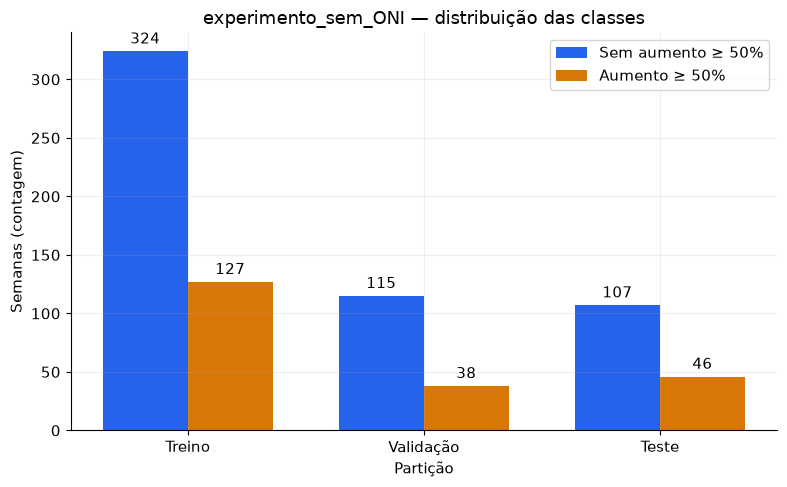

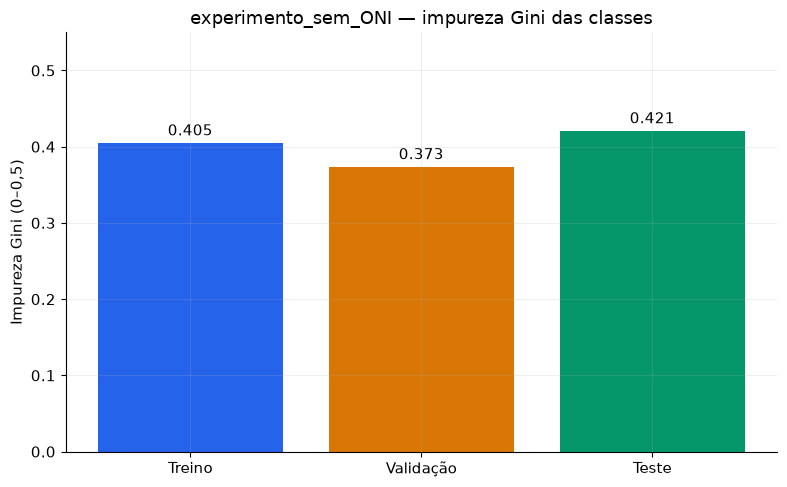

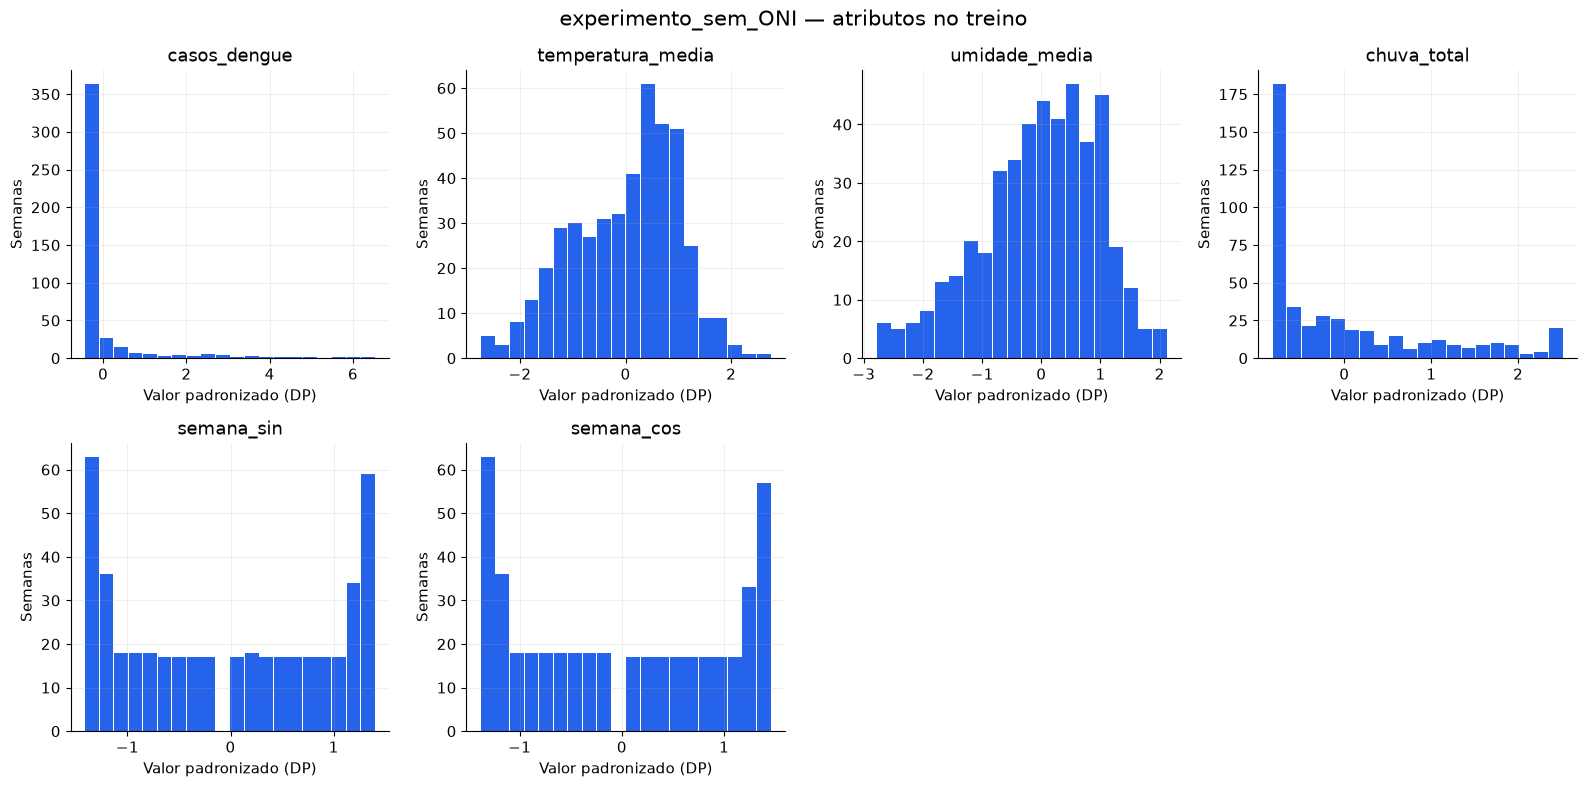

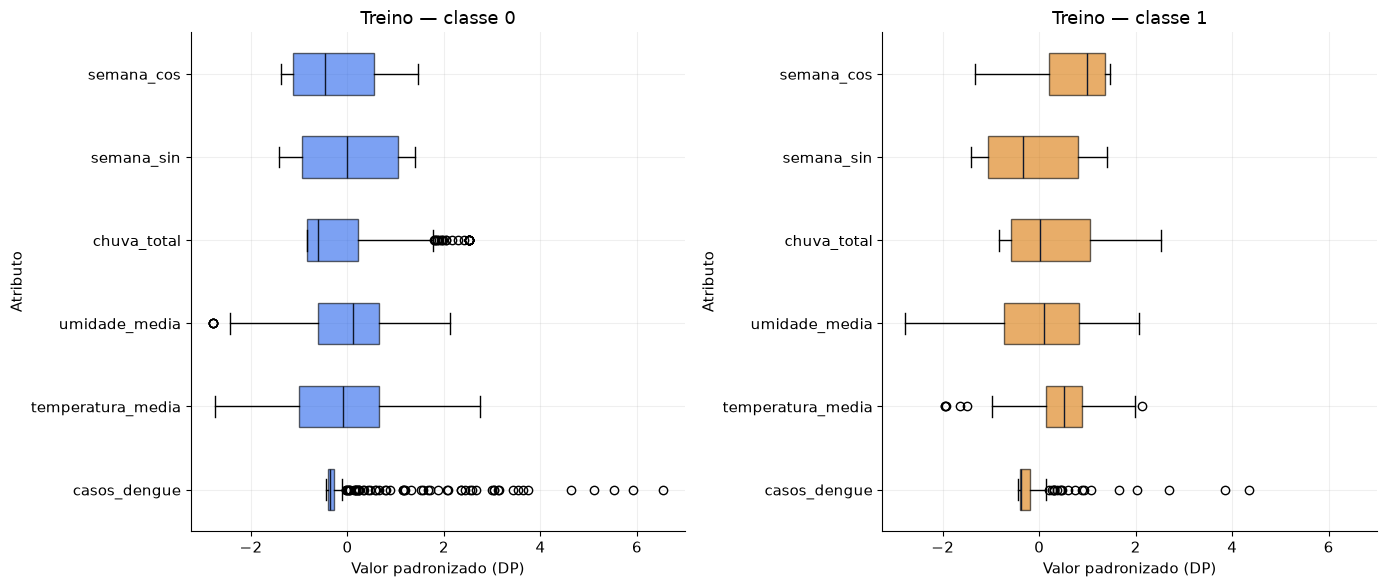

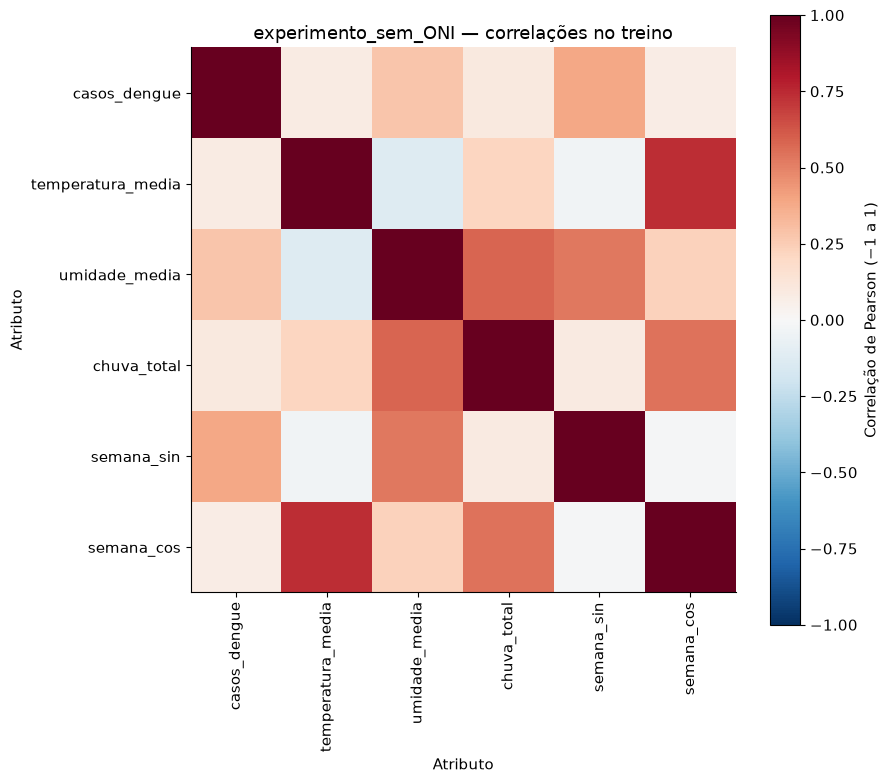

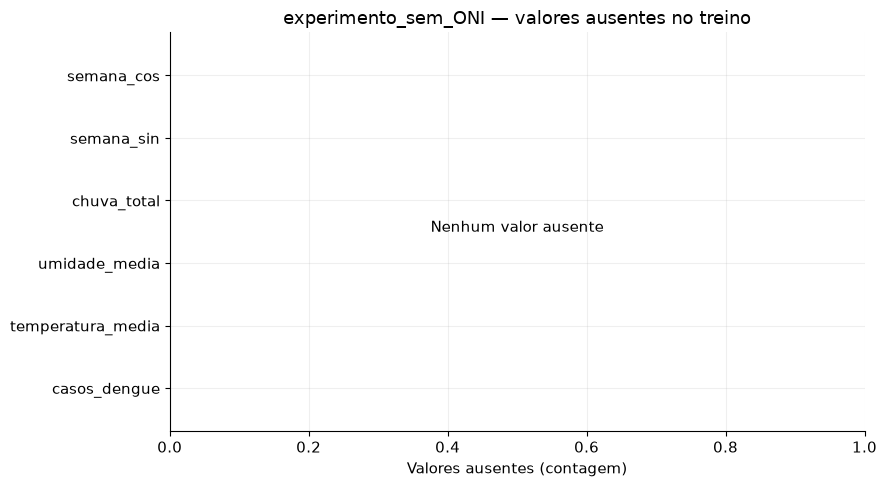

In [5]:
# EDA sobre a última observação de cada janela do treino, na escala padronizada.
# Não seleciona atributos e não altera o treinamento.
eda_dir = RESULTS_ROOT / 'eda'
eda_dir.mkdir(exist_ok=True)
DIRS = {'figures': RESULTS_ROOT / 'figures'}
DIRS['figures'].mkdir(exist_ok=True)
train_last = pd.DataFrame(X_sequence['treino'][:, -1, :], columns=input_features)
train_last.describe().T.rename_axis('feature').to_csv(eda_dir / 'estatisticas_treino.csv')
class_rows = []
for split in SPLIT_LABELS:
    counts = np.bincount(y[split], minlength=2)
    class_rows.extend({'split': split, 'class_id': cls, 'count': int(counts[cls]),
                       'proportion': float(counts[cls]/counts.sum())} for cls in [0,1])
class_frame = pd.DataFrame(class_rows)
class_frame.to_csv(eda_dir / 'distribuicao_classes.csv', index=False)
fig, ax = plt.subplots(figsize=(8,5))
for cls, shift, color, label in [(0,-.18,'sem_aumento','Sem aumento ≥ 50%'), (1,.18,'aumento','Aumento ≥ 50%')]:
    subset = class_frame[class_frame.class_id == cls]
    bars = ax.bar(np.arange(3)+shift, subset['count'], width=.36, color=COLORS[color], label=label)
    ax.bar_label(bars, padding=3)
ax.set(title=f'{EXPERIMENT_NAME} — distribuição das classes', xticks=np.arange(3),
       xticklabels=list(SPLIT_LABELS.values()), xlabel='Partição', ylabel='Semanas (contagem)')
ax.legend()
save_figure(fig, '00_distribuicao_classes')

gini = class_frame.groupby('split',sort=False).proportion.apply(lambda p: 1-np.sum(p**2)).rename('gini_impurity')
gini.to_csv(eda_dir / 'gini_classes.csv')
fig, ax = plt.subplots(figsize=(8,5))
bars=ax.bar([SPLIT_LABELS[s] for s in gini.index], gini, color=[COLORS[s] for s in gini.index])
ax.bar_label(bars,fmt='%.3f',padding=3)
ax.set(title=f'{EXPERIMENT_NAME} — impureza Gini das classes', ylabel='Impureza Gini (0–0,5)',ylim=(0,.55))
save_figure(fig,'00_gini_classes')

hist_rows=[]
fig, axes=plt.subplots(2,4,figsize=(16,8))
for ax, col in zip(axes.flat,input_features):
    counts,edges=np.histogram(train_last[col],bins=20)
    centers=(edges[1:]+edges[:-1])/2
    ax.bar(centers,counts,width=np.diff(edges)*.95,color=COLORS['dados'])
    ax.set(title=col,xlabel='Valor padronizado (DP)',ylabel='Semanas')
    hist_rows.extend({'feature':col,'bin_left':float(a),'bin_right':float(b),'bin_center':float(c),'count':int(n)}
                     for a,b,c,n in zip(edges[:-1],edges[1:],centers,counts))
for ax in list(axes.flat)[len(input_features):]:ax.set_visible(False)
fig.suptitle(f'{EXPERIMENT_NAME} — atributos no treino',fontsize=15)
pd.DataFrame(hist_rows).to_csv(eda_dir / 'histogramas_treino.csv',index=False)
save_figure(fig,'00_histogramas_treino')

from matplotlib.cbook import boxplot_stats
box_rows,outliers=[],[]
fig,axes=plt.subplots(1,2,figsize=(14,6),sharex=True)
for ax,cls,key in zip(axes,[0,1],['sem_aumento','aumento']):
    stats=[]
    for col in input_features:
        stat=boxplot_stats(train_last.loc[y['treino']==cls,col],whis=1.5)[0]
        stat['label']=col;stats.append(stat)
        box_rows.append({'feature':col,'class_id':cls,**{k:float(stat[k]) for k in ['mean','med','q1','q3','whislo','whishi']}})
        outliers.extend({'feature':col,'class_id':cls,'value':float(v)} for v in stat['fliers'])
    artists=ax.bxp(stats,orientation='horizontal',patch_artist=True,medianprops={'color':'#0F172A'})
    for box in artists['boxes']:box.set_facecolor(COLORS[key]);box.set_alpha(.6)
    ax.set(title=f'Treino — classe {cls}',xlabel='Valor padronizado (DP)',ylabel='Atributo')
pd.DataFrame(box_rows).to_csv(eda_dir / 'boxplots_treino.csv',index=False)
pd.DataFrame(outliers,columns=['feature','class_id','value']).to_csv(eda_dir / 'boxplots_outliers.csv',index=False)
save_figure(fig,'00_boxplots_treino')

corr=train_last.corr()
pd.DataFrame([{'feature_x':x,'feature_y':z,'correlation':float(corr.loc[z,x])} for z in input_features for x in input_features]).to_csv(eda_dir / 'correlacoes_treino.csv',index=False)
fig,ax=plt.subplots(figsize=(9,8))
im=ax.imshow(corr,cmap='RdBu_r',vmin=-1,vmax=1)
ax.set(xticks=range(len(input_features)),yticks=range(len(input_features)),xticklabels=input_features,yticklabels=input_features,
       title=f'{EXPERIMENT_NAME} — correlações no treino',xlabel='Atributo',ylabel='Atributo')
ax.tick_params(axis='x',rotation=90);ax.grid(False)
fig.colorbar(im,ax=ax,label='Correlação de Pearson (−1 a 1)')
save_figure(fig,'00_correlacoes_treino')

missing=pd.DataFrame({'feature':input_features,'missing_count':train_last.isna().sum().to_numpy()})
missing.to_csv(eda_dir / 'valores_ausentes_treino.csv',index=False)
fig,ax=plt.subplots(figsize=(9,5))
ax.barh(missing.feature,missing.missing_count,color=COLORS['dados'])
ax.set(title=f'{EXPERIMENT_NAME} — valores ausentes no treino',xlabel='Valores ausentes (contagem)',xlim=(0,1))
ax.text(.5,.5,'Nenhum valor ausente',transform=ax.transAxes,ha='center')
save_figure(fig,'00_valores_ausentes')

In [6]:
model_metrics = {}
selected_models = {}

## 5. Random Forest

Arquitetura, treinamento, validação, teste e explicabilidade.

In [7]:
MODEL_KEY = 'random_forest'
MODEL_TITLE = 'Random Forest'
RESULTS = RESULTS_ROOT / MODEL_KEY
DIRS = {name: RESULTS / name for name in ['data','metrics','figures','explainability','artifacts']}
for directory in DIRS.values():directory.mkdir(parents=True,exist_ok=True)
joblib.dump(scaler,DIRS['artifacts'] / 'scaler.joblib')
samples.to_csv(DIRS['data'] / 'amostras_e_particoes.csv')
for split in SPLIT_LABELS:
    values=pd.DataFrame(X[split],columns=feature_names,index=split_ids[split])
    values.index.name='sample_id'
    values['target']=y[split]
    values.to_csv(DIRS['data'] / f'{split}_padronizado.csv')

### 5.1. Arquitetura básica

In [8]:
from sklearn.ensemble import RandomForestClassifier
TREE_COUNTS = [25, 50, 100, 200]

def create_model(n_trees):
    return RandomForestClassifier(n_estimators=n_trees, max_depth=6,
        min_samples_leaf=2, class_weight='balanced', random_state=SEED, n_jobs=1)

display(create_model(TREE_COUNTS[0]))

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",25
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_feature

### 5.2. Treinamento e seleção na validação

Maior F1 de validação; em empate, preserva-se o primeiro modelo. Limiar fixo de 0,5.

In [9]:
# Número de árvores escolhido somente pelo F1 de validação. Teste permanece fechado.
history_rows = []
best_score = -np.inf
for n_trees in TREE_COUNTS:
    candidate = create_model(n_trees)
    candidate.fit(X['treino'], y['treino'])
    for split in ['treino', 'validacao']:
        prob = candidate.predict_proba(X[split])[:, 1]
        scores = calculate_metrics(y[split], prob)
        history_rows.append({'step': n_trees, 'split': split, **scores})
        if split == 'validacao' and scores['f1'] > best_score:
            best_score = scores['f1']
            selected_step = n_trees
            model = copy.deepcopy(candidate)
history = pd.DataFrame(history_rows)
history.to_csv(DIRS['metrics'] / 'historico_treinamento.csv', index=False)
joblib.dump(model, DIRS['artifacts'] / 'model.joblib')
print(f'Modelo selecionado: {selected_step} árvores; F1 validação = {best_score:.3f}')

Modelo selecionado: 200 árvores; F1 validação = 0.699


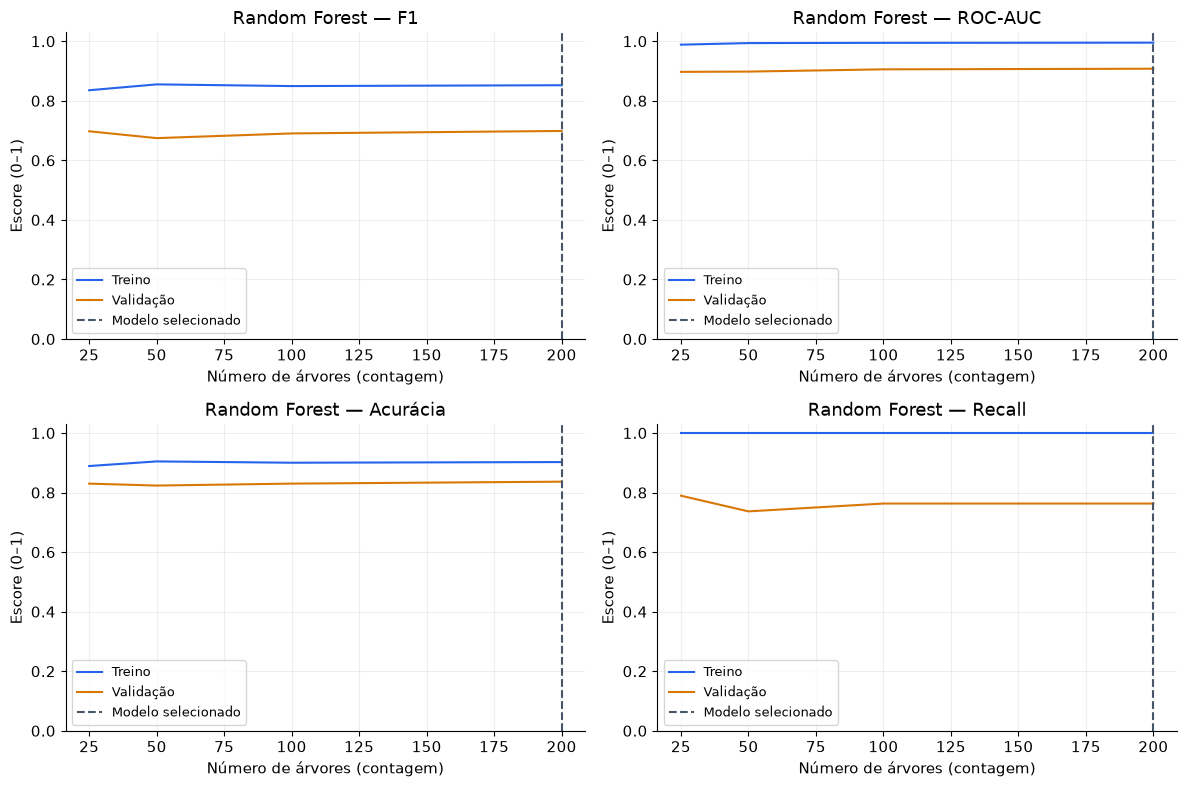

In [10]:
STEP_LABEL = "Número de árvores (contagem)"

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (metric, label) in zip(axes.flat, METRIC_LABELS.items()):
    for split in ['treino', 'validacao']:
        subset = history[history.split == split]
        ax.plot(subset.step, subset[metric], color=COLORS[split], label=SPLIT_LABELS[split])
    ax.axvline(selected_step, color='#475569', linestyle='--', label='Modelo selecionado')
    ax.set(title=f'{MODEL_TITLE} — {label}', xlabel=STEP_LABEL, ylabel='Escore (0–1)', ylim=(0, 1.03))
    ax.legend(fontsize=9)
save_figure(fig, '01_historico_metricas')

### 5.3. Validação e teste

,f1,roc_auc,accuracy,recall
split,,,,
treino,0.8523,0.9953,0.9024,1.0000
validacao,0.6988,0.9078,0.8366,0.7632
teste,0.7042,0.9303,0.8627,0.5435


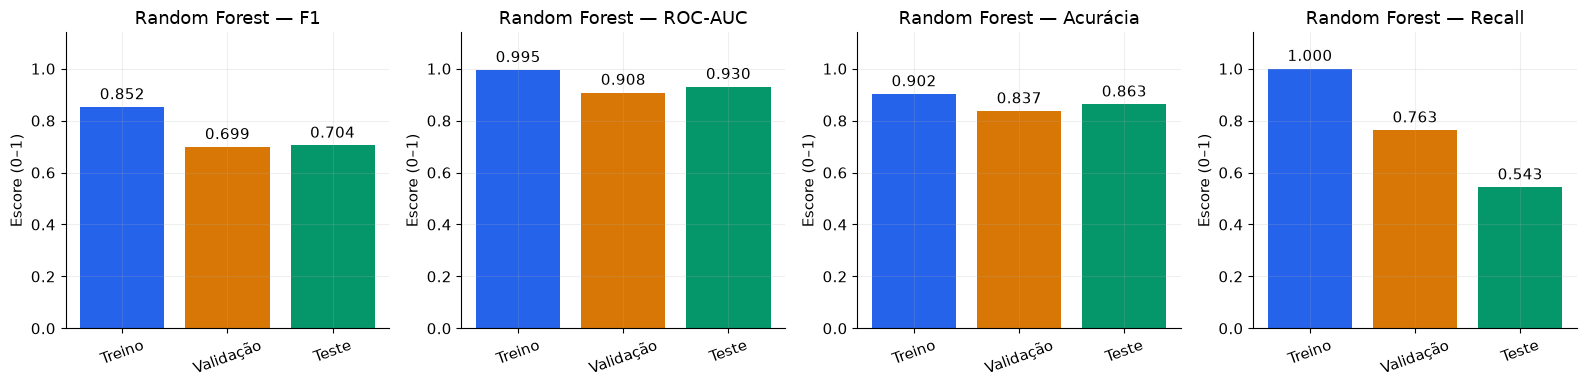

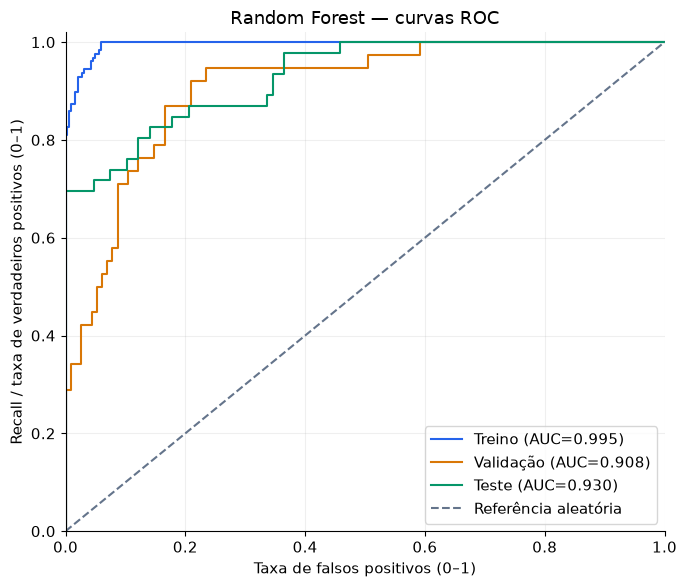

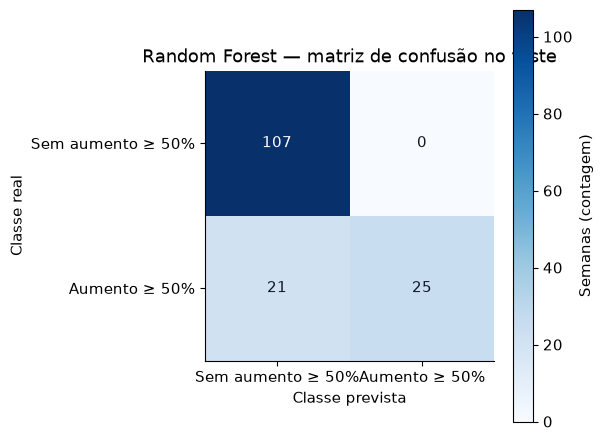

In [11]:
# Avaliação final: nenhuma decisão de seleção é tomada usando o teste.
probabilities = {}
for split in split_ids:
    probabilities[split] = model.predict_proba(X[split])[:, 1]
metric_rows = []
roc_rows = []
reports = {}
for split, prob in probabilities.items():
    assert len(prob) == len(y[split]) and np.isfinite(prob).all()
    metric_rows.append({'split': split, **calculate_metrics(y[split], prob)})
    prediction = (prob >= THRESHOLD).astype(int)
    pd.DataFrame({'sample_id': split_ids[split], 'target': y[split],
        'probability_positive': prob, 'prediction': prediction}).to_csv(
            DIRS['data'] / f'previsoes_{split}.csv', index=False)
    fpr, tpr, thresholds = roc_curve(y[split], prob)
    roc_rows.extend({'split': split, 'false_positive_rate': float(a),
        'true_positive_rate': float(b), 'threshold': float(c) if np.isfinite(c) else None}
        for a, b, c in zip(fpr, tpr, thresholds))
    pd.DataFrame(confusion_matrix(y[split], prediction, labels=[0, 1]),
        index=['real_sem_aumento', 'real_aumento'], columns=['previsto_sem_aumento', 'previsto_aumento']).to_csv(
            DIRS['metrics'] / f'matriz_confusao_{split}.csv')
    reports[split] = classification_report(y[split], prediction, labels=[0, 1],
        target_names=['sem_aumento', 'aumento'], output_dict=True, zero_division=0)
metrics = pd.DataFrame(metric_rows).set_index('split')
metrics.to_csv(DIRS['metrics'] / 'metricas_finais.csv')
pd.DataFrame(roc_rows).to_csv(DIRS['metrics'] / 'curvas_roc.csv', index=False)
(DIRS['metrics'] / 'relatorios_classificacao.json').write_text(
    json.dumps(reports, indent=2, ensure_ascii=False, allow_nan=False), encoding='utf-8')
display(metrics.round(4))

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (metric, label) in zip(axes, METRIC_LABELS.items()):
    bars = ax.bar([SPLIT_LABELS[s] for s in metrics.index], metrics[metric],
                  color=[COLORS[s] for s in metrics.index])
    ax.set(title=f'{MODEL_TITLE} — {label}', ylabel='Escore (0–1)', ylim=(0, 1.14))
    ax.tick_params(axis='x', rotation=20)
    ax.bar_label(bars, fmt='%.3f', padding=3)
save_figure(fig, '02_metricas_finais')

fig, ax = plt.subplots(figsize=(7, 6))
for split, prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y[split], prob)
    ax.plot(fpr, tpr, color=COLORS[split],
            label=f'{SPLIT_LABELS[split]} (AUC={metrics.loc[split, "roc_auc"]:.3f})')
ax.plot([0, 1], [0, 1], '--', color='#64748B', label='Referência aleatória')
ax.set(title=f'{MODEL_TITLE} — curvas ROC', xlabel='Taxa de falsos positivos (0–1)',
       ylabel='Recall / taxa de verdadeiros positivos (0–1)', xlim=(0, 1), ylim=(0, 1.02))
ax.legend()
save_figure(fig, '03_curvas_roc')

cm = confusion_matrix(y['teste'], (probabilities['teste'] >= THRESHOLD).astype(int), labels=[0, 1])
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap='Blues')
for (i, j), value in np.ndenumerate(cm):
    ax.text(j, i, str(value), ha='center', va='center', color='white' if value > cm.max()/2 else '#0F172A')
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['Sem aumento ≥ 50%', 'Aumento ≥ 50%'],
       yticklabels=['Sem aumento ≥ 50%', 'Aumento ≥ 50%'], xlabel='Classe prevista', ylabel='Classe real',
       title=f'{MODEL_TITLE} — matriz de confusão no teste')
ax.grid(False)
fig.colorbar(im, ax=ax, label='Semanas (contagem)')
save_figure(fig, '04_matriz_confusao_teste')

### 5.4. Explicabilidade

In [12]:
def export_attributions(values, method, units):
    assert values.shape == X['teste'].shape
    assert np.isfinite(values).all()
    local = pd.DataFrame(values, columns=feature_names, index=test_ids)
    local.index.name = 'sample_id'
    local.to_csv(DIRS['explainability'] / f'{method}_atribuicoes.csv')
    importance = pd.DataFrame({'feature': feature_names,
        'mean_absolute_attribution': np.abs(values).mean(axis=0),
        'mean_signed_attribution': values.mean(axis=0)}).sort_values(
            'mean_absolute_attribution', ascending=False)
    importance.to_csv(DIRS['explainability'] / f'{method}_importancia.csv', index=False)
    top = importance.head(15).iloc[::-1]
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(top.feature, top.mean_absolute_attribution, color=COLORS[method])
    ax.set(title=f'{MODEL_TITLE} — {method.replace("_", " ").title()} — teste',
           xlabel=f'Média da atribuição absoluta ({units})', ylabel='Atributo padronizado')
    save_figure(fig, f'05_{method}_importancia')
    display(importance.head(10))
    return importance

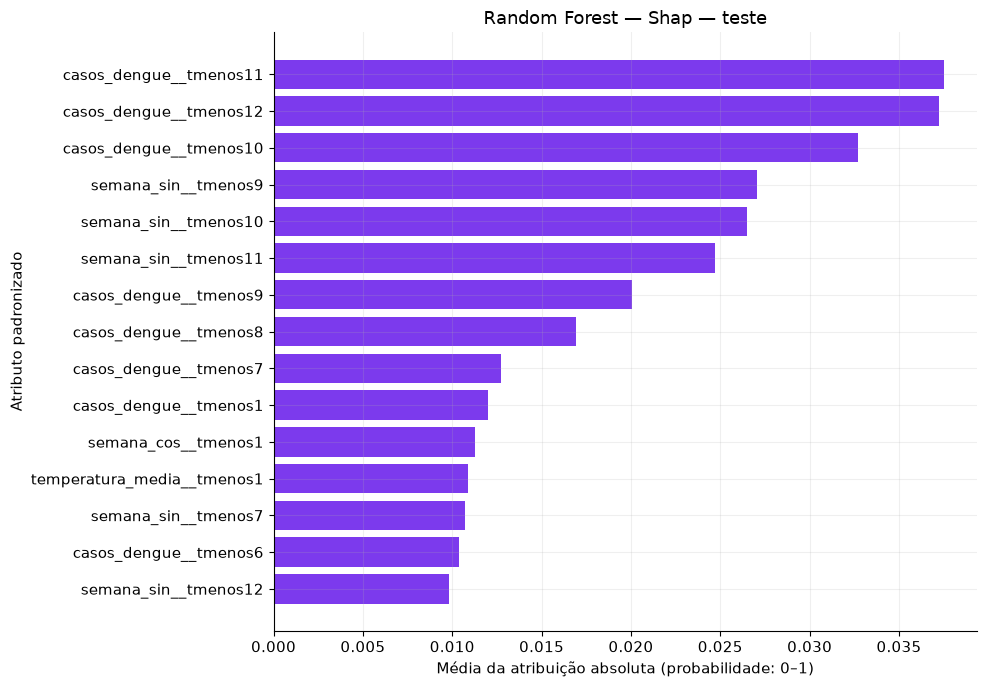

,feature,mean_absolute_attribution,mean_signed_attribution
6,casos_dengue__tmenos11,0.037491,-0.036943
0,casos_dengue__tmenos12,0.037230,-0.036722
12,casos_dengue__tmenos10,0.032685,-0.032393
22,semana_sin__tmenos9,0.027061,-0.004227
16,semana_sin__tmenos10,0.026497,-0.003978
10,semana_sin__tmenos11,0.024712,-0.004484
18,casos_dengue__tmenos9,0.020050,-0.019885
24,casos_dengue__tmenos8,0.016902,-0.016724
30,casos_dengue__tmenos7,0.012723,-0.012646
66,casos_dengue__tmenos1,0.012017,0.011808


In [13]:
# Tree SHAP explica a probabilidade da classe positiva (aumento).
explainer = shap.TreeExplainer(model, model_output='raw', feature_perturbation='tree_path_dependent')
raw_values = explainer.shap_values(X['teste'], check_additivity=True)
if isinstance(raw_values, list):
    shap_values = np.asarray(raw_values[1])
else:
    shap_values = np.asarray(raw_values)[:, :, 1]
base_value = float(np.asarray(explainer.expected_value)[1])
reconstructed = base_value + shap_values.sum(axis=1)
assert np.allclose(reconstructed, probabilities['teste'], atol=1e-5)
export_attributions(shap_values, 'shap', 'probabilidade: 0–1')
pd.DataFrame({'sample_id': test_ids, 'base_probability': base_value,
    'sum_attributions': shap_values.sum(axis=1), 'reconstructed_probability': reconstructed,
    'absolute_error': np.abs(reconstructed - probabilities['teste'])}).to_csv(
        DIRS['explainability'] / 'shap_aditividade.csv', index=False)

Importância Gini (MDI): as importâncias somam 1. Barras indicam DP entre árvores,
            não intervalo de confiança. É uma medida do modelo e pode ser afetada por
            cardinalidade e correlação entre atributos.

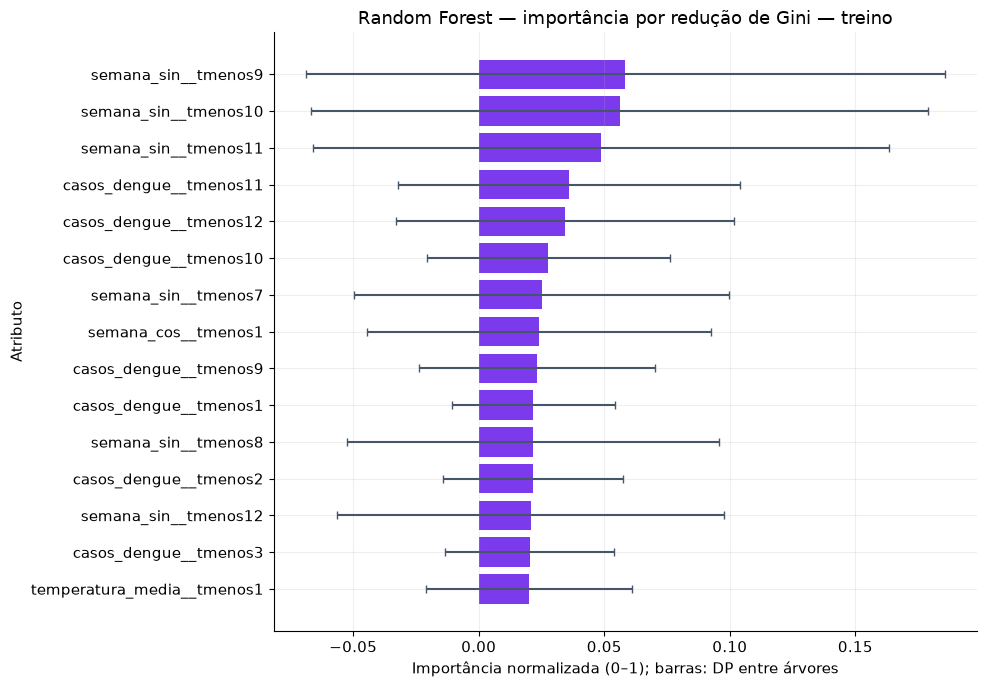

,feature,importance,std_across_trees
22,semana_sin__tmenos9,0.058362,0.127333
16,semana_sin__tmenos10,0.056156,0.122815
10,semana_sin__tmenos11,0.048639,0.114549
6,casos_dengue__tmenos11,0.036139,0.068101
0,casos_dengue__tmenos12,0.034304,0.067396
12,casos_dengue__tmenos10,0.027617,0.048403
34,semana_sin__tmenos7,0.025098,0.074726
71,semana_cos__tmenos1,0.024066,0.068594
18,casos_dengue__tmenos9,0.023026,0.046982
66,casos_dengue__tmenos1,0.021771,0.032555


In [14]:
# Importância MDI: redução média ponderada da impureza Gini no treino.
assert model.criterion == 'gini'
tree_importances = np.array([tree.feature_importances_ for tree in model.estimators_])
gini_importance = pd.DataFrame({'feature': feature_names,
    'importance': model.feature_importances_,
    'std_across_trees': tree_importances.std(axis=0)}).sort_values('importance', ascending=False)
gini_importance.to_csv(DIRS['explainability'] / 'gini_importancia.csv', index=False)
assert np.isclose(gini_importance.importance.sum(), 1.0)
top = gini_importance.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top.feature, top.importance, xerr=top.std_across_trees,
         color=COLORS['gini'], error_kw={'ecolor': '#475569', 'capsize': 3})
ax.set(title=f'{MODEL_TITLE} — importância por redução de Gini — treino',
       xlabel='Importância normalizada (0–1); barras: DP entre árvores', ylabel='Atributo')
save_figure(fig, '06_gini_importancia')
display(gini_importance.head(15))

### 5.5. Exportação do modelo e metadados

In [15]:
metadata = {'model':MODEL_KEY,'experiment':EXPERIMENT_NAME,'include_oni':INCLUDE_ONI,
    'dataset':str(DATA_PATH.relative_to(PROJECT_ROOT)), 'seed':SEED,
    'positive_class':'aumento de pelo menos 50% nos casos',
    'target_definition':'casos(t+4) >= 1.5 × média de casos(t−4 ... t−1)',
    'horizon_weeks':HORIZON_WEEKS,'growth_fraction':GROWTH_FRACTION,
    'baseline_weeks':BASELINE_WEEKS,'threshold':THRESHOLD,'selection_metric':'validation_f1',
    'selected_step':int(selected_step),'sequence_length':SEQUENCE_LENGTH,
    'input_features':input_features,'features':feature_names,'availability_lags_weeks':availability_lags,
    'train_end':train_end.date().isoformat(),'validation_end':validation_end.date().isoformat(),
    'test_used_for_selection':False,'colors':COLORS,'font':'DejaVu Sans',
    'units':{'metrics':'escore (0–1)','probabilities':'0–1','casos_dengue':'casos por semana',
      'temperatura_media':'°C','umidade_media':'%','chuva_total':'mm por semana',
      'ONI':'°C (anomalia do índice, conforme a coluna da base)',
      'semana_sin':'adimensional','semana_cos':'adimensional','processed_features':'desvios padrão (DP)',
      'shap':'probabilidade positiva (0–1)','saliency':'logit por unidade padronizada',
      'integrated_gradients':'logit','gini':'importância normalizada (0–1)'},
    'versions':{p:importlib.metadata.version(p) for p in
       ['numpy','pandas','scikit-learn','torch','captum','shap','matplotlib']},
    'limitations':['Aumento de casos é um proxy exploratório; não confirma surto epidemiológico.',
                   'Latências de uma semana (casos/clima) e quatro semanas (ONI) são hipóteses de disponibilidade.',
                   'Um município, uma divisão temporal e uma semente; comparação exploratória.']}
(RESULTS / 'metadata.json').write_text(json.dumps(metadata,indent=2,ensure_ascii=False,allow_nan=False),encoding='utf-8')
model_metrics[MODEL_KEY]=metrics.copy()
selected_models[MODEL_KEY]=model

## 6. RNN

Arquitetura, treinamento, validação, teste e explicabilidade.

In [16]:
MODEL_KEY = 'rnn'
MODEL_TITLE = 'RNN'
RESULTS = RESULTS_ROOT / MODEL_KEY
DIRS = {name: RESULTS / name for name in ['data','metrics','figures','explainability','artifacts']}
for directory in DIRS.values():directory.mkdir(parents=True,exist_ok=True)
joblib.dump(scaler,DIRS['artifacts'] / 'scaler.joblib')
samples.to_csv(DIRS['data'] / 'amostras_e_particoes.csv')
for split in SPLIT_LABELS:
    values=pd.DataFrame(X[split],columns=feature_names,index=split_ids[split])
    values.index.name='sample_id'
    values['target']=y[split]
    values.to_csv(DIRS['data'] / f'{split}_padronizado.csv')

### 6.1. Arquitetura básica

In [17]:
torch.manual_seed(SEED)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
DEVICE = torch.device('cpu')
MAX_EPOCHS = 150
PATIENCE = 20
LEARNING_RATE = 0.003
HIDDEN_SIZE = 24

class SequenceClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.recurrent = nn.RNN(input_size=len(input_features), hidden_size=HIDDEN_SIZE,
                                   num_layers=1, batch_first=True)
        self.output = nn.Linear(HIDDEN_SIZE, 1)

    def forward(self, inputs):
        sequence_output, _ = self.recurrent(inputs)
        return self.output(sequence_output[:, -1, :]).squeeze(-1)

# Sequências temporais reais com 12 semanas.
tensors = {split: torch.tensor(values, device=DEVICE) for split, values in X_sequence.items()}
targets = {split: torch.tensor(values, dtype=torch.float32, device=DEVICE) for split, values in y.items()}
model = SequenceClassifier().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = nn.BCEWithLogitsLoss()
print(model)
print('Formato de entrada (amostras, passos, atributos):', tuple(tensors['treino'].shape))

SequenceClassifier(
  (recurrent): RNN(6, 24, batch_first=True)
  (output): Linear(in_features=24, out_features=1, bias=True)
)
Formato de entrada (amostras, passos, atributos): (451, 12, 6)


### 6.2. Treinamento e seleção na validação

Maior F1 de validação; em empate, preserva-se o primeiro modelo. Limiar fixo de 0,5.

In [18]:
history_rows = []
best_score = -np.inf
best_state = None
epochs_without_improvement = 0
for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    optimizer.zero_grad()
    loss = criterion(model(tensors['treino']), targets['treino'])
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optimizer.step()
    model.eval()
    with torch.no_grad():
        for split in ['treino', 'validacao']:
            logits = model(tensors[split])
            prob = torch.sigmoid(logits).cpu().numpy()
            scores = calculate_metrics(y[split], prob)
            history_rows.append({'step': epoch, 'split': split,
                'loss': criterion(logits, targets[split]).item(), **scores})
            if split == 'validacao':
                val_f1 = scores['f1']
    if val_f1 > best_score + 1e-8:
        best_score = val_f1
        selected_step = epoch
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
    if epochs_without_improvement >= PATIENCE:
        break
model.load_state_dict(best_state)
model.eval()
history = pd.DataFrame(history_rows)
history.to_csv(DIRS['metrics'] / 'historico_treinamento.csv', index=False)
torch.save({'state_dict': model.state_dict(), 'model_type': MODEL_KEY,
            'input_size': len(input_features), 'hidden_size': HIDDEN_SIZE,
            'sequence_length': SEQUENCE_LENGTH, 'feature_names': feature_names}, DIRS['artifacts'] / 'model.pt')
print(f'Época selecionada: {selected_step}; F1 validação = {best_score:.3f}')

Época selecionada: 17; F1 validação = 0.692


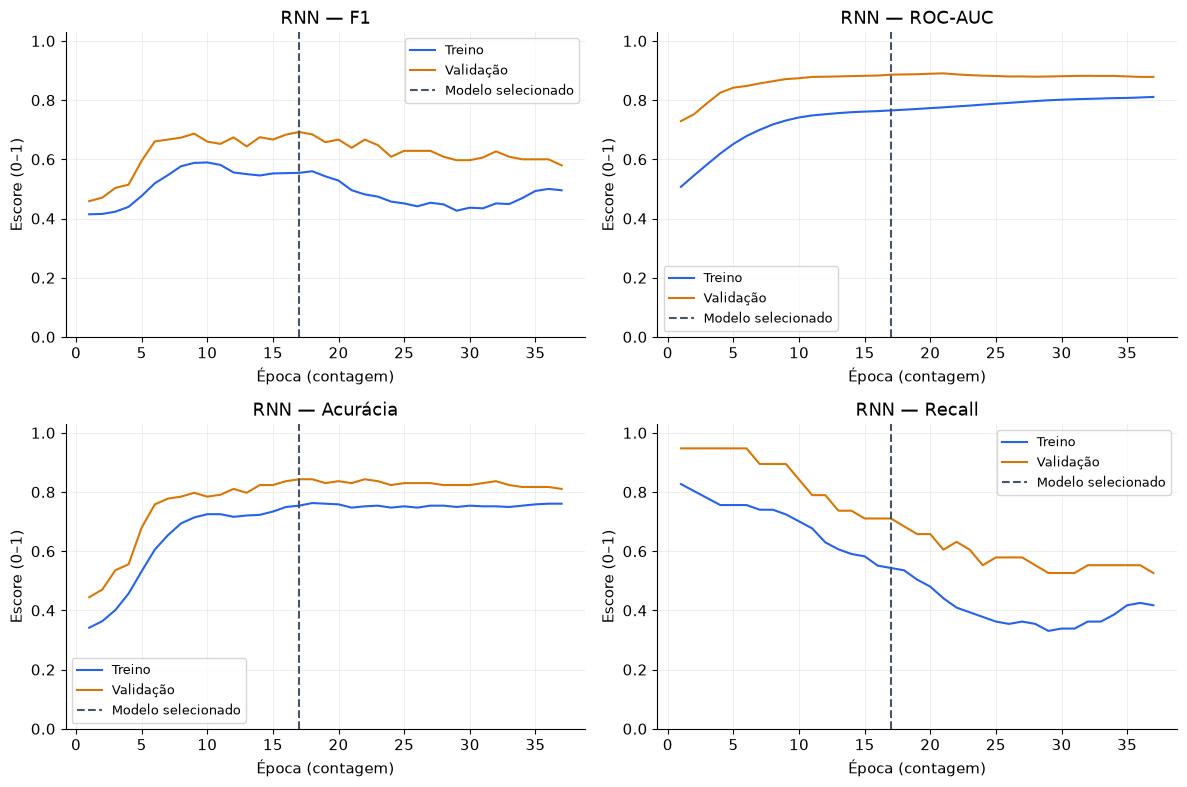

In [19]:
STEP_LABEL = "Época (contagem)"

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (metric, label) in zip(axes.flat, METRIC_LABELS.items()):
    for split in ['treino', 'validacao']:
        subset = history[history.split == split]
        ax.plot(subset.step, subset[metric], color=COLORS[split], label=SPLIT_LABELS[split])
    ax.axvline(selected_step, color='#475569', linestyle='--', label='Modelo selecionado')
    ax.set(title=f'{MODEL_TITLE} — {label}', xlabel=STEP_LABEL, ylabel='Escore (0–1)', ylim=(0, 1.03))
    ax.legend(fontsize=9)
save_figure(fig, '01_historico_metricas')

### 6.3. Validação e teste

,f1,roc_auc,accuracy,recall
split,,,,
treino,0.5542,0.7652,0.7539,0.5433
validacao,0.6923,0.8860,0.8431,0.7105
teste,0.8090,0.9173,0.8889,0.7826


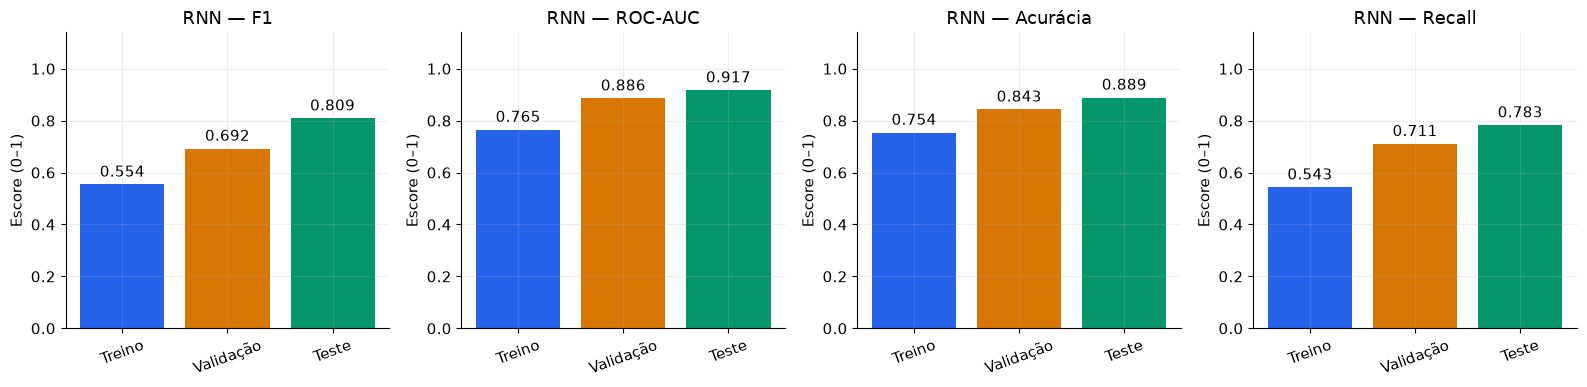

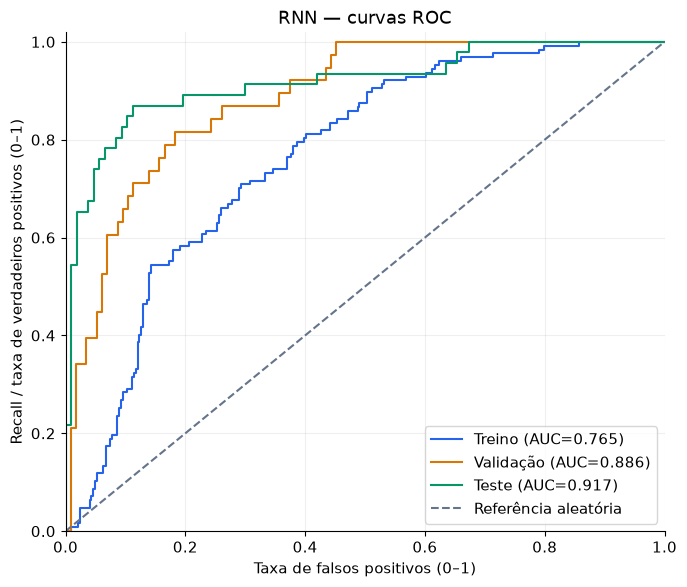

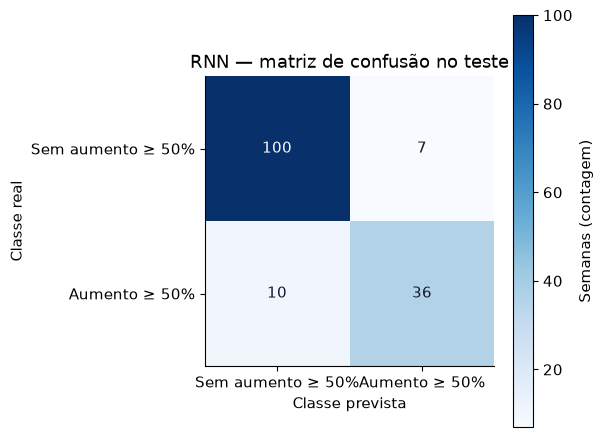

In [20]:
# Avaliação final: nenhuma decisão de seleção é tomada usando o teste.
probabilities = {}
for split in split_ids:
    with torch.no_grad():
        probabilities[split] = torch.sigmoid(model(tensors[split])).cpu().numpy()
metric_rows = []
roc_rows = []
reports = {}
for split, prob in probabilities.items():
    assert len(prob) == len(y[split]) and np.isfinite(prob).all()
    metric_rows.append({'split': split, **calculate_metrics(y[split], prob)})
    prediction = (prob >= THRESHOLD).astype(int)
    pd.DataFrame({'sample_id': split_ids[split], 'target': y[split],
        'probability_positive': prob, 'prediction': prediction}).to_csv(
            DIRS['data'] / f'previsoes_{split}.csv', index=False)
    fpr, tpr, thresholds = roc_curve(y[split], prob)
    roc_rows.extend({'split': split, 'false_positive_rate': float(a),
        'true_positive_rate': float(b), 'threshold': float(c) if np.isfinite(c) else None}
        for a, b, c in zip(fpr, tpr, thresholds))
    pd.DataFrame(confusion_matrix(y[split], prediction, labels=[0, 1]),
        index=['real_sem_aumento', 'real_aumento'], columns=['previsto_sem_aumento', 'previsto_aumento']).to_csv(
            DIRS['metrics'] / f'matriz_confusao_{split}.csv')
    reports[split] = classification_report(y[split], prediction, labels=[0, 1],
        target_names=['sem_aumento', 'aumento'], output_dict=True, zero_division=0)
metrics = pd.DataFrame(metric_rows).set_index('split')
metrics.to_csv(DIRS['metrics'] / 'metricas_finais.csv')
pd.DataFrame(roc_rows).to_csv(DIRS['metrics'] / 'curvas_roc.csv', index=False)
(DIRS['metrics'] / 'relatorios_classificacao.json').write_text(
    json.dumps(reports, indent=2, ensure_ascii=False, allow_nan=False), encoding='utf-8')
display(metrics.round(4))

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (metric, label) in zip(axes, METRIC_LABELS.items()):
    bars = ax.bar([SPLIT_LABELS[s] for s in metrics.index], metrics[metric],
                  color=[COLORS[s] for s in metrics.index])
    ax.set(title=f'{MODEL_TITLE} — {label}', ylabel='Escore (0–1)', ylim=(0, 1.14))
    ax.tick_params(axis='x', rotation=20)
    ax.bar_label(bars, fmt='%.3f', padding=3)
save_figure(fig, '02_metricas_finais')

fig, ax = plt.subplots(figsize=(7, 6))
for split, prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y[split], prob)
    ax.plot(fpr, tpr, color=COLORS[split],
            label=f'{SPLIT_LABELS[split]} (AUC={metrics.loc[split, "roc_auc"]:.3f})')
ax.plot([0, 1], [0, 1], '--', color='#64748B', label='Referência aleatória')
ax.set(title=f'{MODEL_TITLE} — curvas ROC', xlabel='Taxa de falsos positivos (0–1)',
       ylabel='Recall / taxa de verdadeiros positivos (0–1)', xlim=(0, 1), ylim=(0, 1.02))
ax.legend()
save_figure(fig, '03_curvas_roc')

cm = confusion_matrix(y['teste'], (probabilities['teste'] >= THRESHOLD).astype(int), labels=[0, 1])
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap='Blues')
for (i, j), value in np.ndenumerate(cm):
    ax.text(j, i, str(value), ha='center', va='center', color='white' if value > cm.max()/2 else '#0F172A')
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['Sem aumento ≥ 50%', 'Aumento ≥ 50%'],
       yticklabels=['Sem aumento ≥ 50%', 'Aumento ≥ 50%'], xlabel='Classe prevista', ylabel='Classe real',
       title=f'{MODEL_TITLE} — matriz de confusão no teste')
ax.grid(False)
fig.colorbar(im, ax=ax, label='Semanas (contagem)')
save_figure(fig, '04_matriz_confusao_teste')

### 6.4. Explicabilidade

In [21]:
def export_attributions(values, method, units):
    assert values.shape == X['teste'].shape
    assert np.isfinite(values).all()
    local = pd.DataFrame(values, columns=feature_names, index=test_ids)
    local.index.name = 'sample_id'
    local.to_csv(DIRS['explainability'] / f'{method}_atribuicoes.csv')
    importance = pd.DataFrame({'feature': feature_names,
        'mean_absolute_attribution': np.abs(values).mean(axis=0),
        'mean_signed_attribution': values.mean(axis=0)}).sort_values(
            'mean_absolute_attribution', ascending=False)
    importance.to_csv(DIRS['explainability'] / f'{method}_importancia.csv', index=False)
    top = importance.head(15).iloc[::-1]
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(top.feature, top.mean_absolute_attribution, color=COLORS[method])
    ax.set(title=f'{MODEL_TITLE} — {method.replace("_", " ").title()} — teste',
           xlabel=f'Média da atribuição absoluta ({units})', ylabel='Atributo padronizado')
    save_figure(fig, f'05_{method}_importancia')
    display(importance.head(10))
    return importance

/media/lorenzo/SSD/Projetos/ML-Dengue/.venv/lib/python3.12/site-packages/captum/attr/_utils/batching.py:51: UserWarning: Internal batch size cannot be less than the number of input examples. Defaulting to internal batch size of 153 equal to the number of examples.
  warnings.warn(


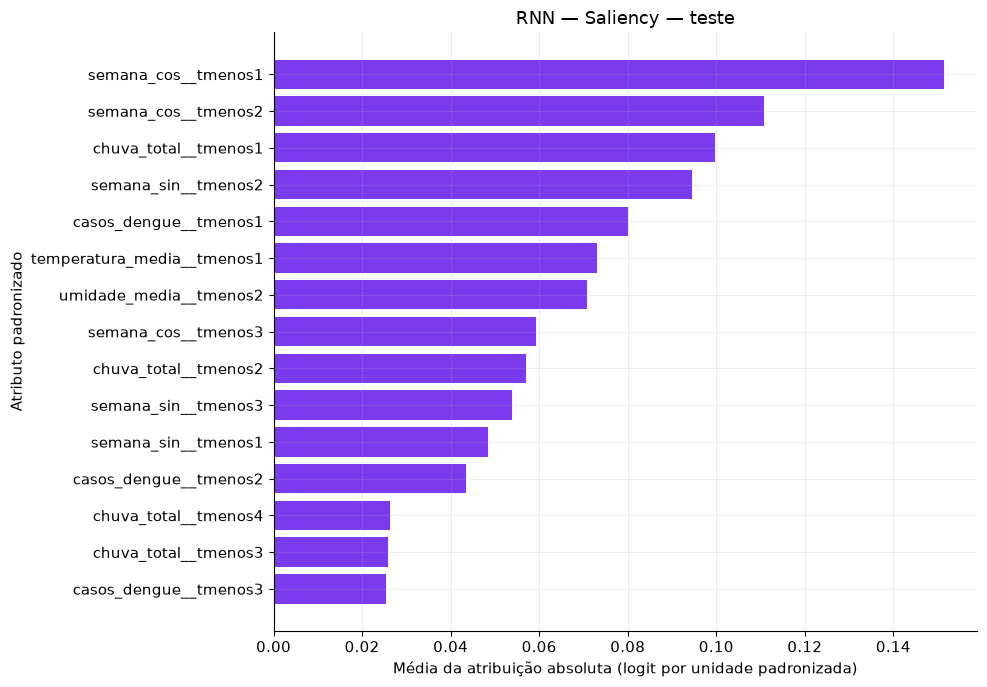

,feature,mean_absolute_attribution,mean_signed_attribution
71,semana_cos__tmenos1,0.151322,0.151322
65,semana_cos__tmenos2,0.110709,0.110709
69,chuva_total__tmenos1,0.099815,0.099815
64,semana_sin__tmenos2,0.094424,-0.094424
66,casos_dengue__tmenos1,0.080103,-0.080103
67,temperatura_media__tmenos1,0.073016,0.073016
62,umidade_media__tmenos2,0.070735,-0.070735
59,semana_cos__tmenos3,0.059174,0.059174
63,chuva_total__tmenos2,0.057074,0.057074
58,semana_sin__tmenos3,0.053867,-0.053867


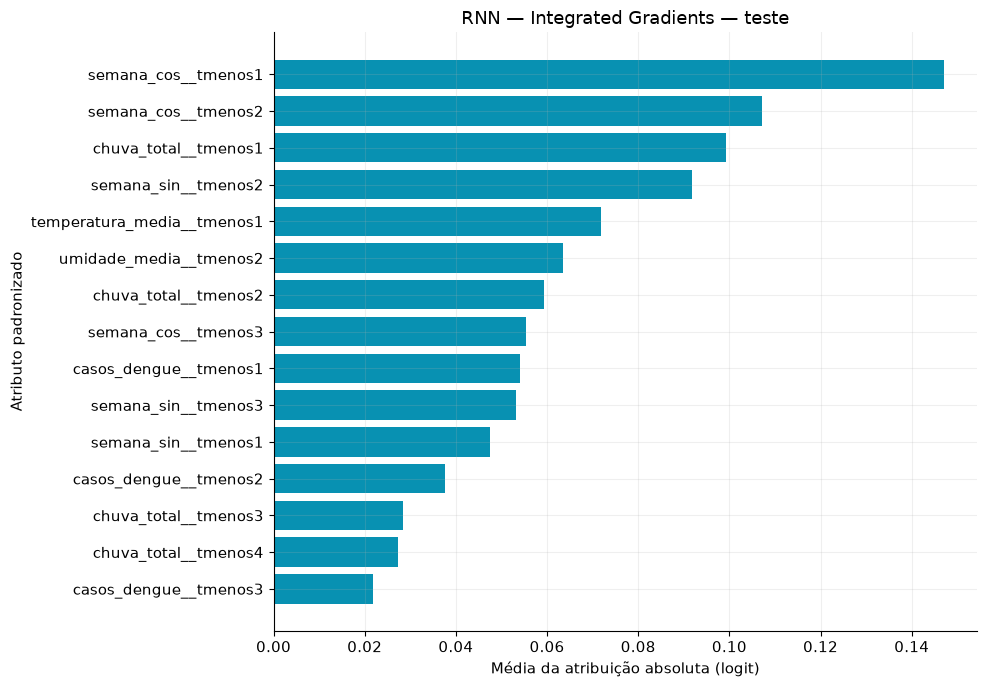

,feature,mean_absolute_attribution,mean_signed_attribution
71,semana_cos__tmenos1,0.146967,0.023428
65,semana_cos__tmenos2,0.107245,0.030081
69,chuva_total__tmenos1,0.099166,0.002808
64,semana_sin__tmenos2,0.091863,0.011886
67,temperatura_media__tmenos1,0.071878,0.030159
62,umidade_media__tmenos2,0.063556,0.024216
63,chuva_total__tmenos2,0.059236,0.002915
59,semana_cos__tmenos3,0.055309,0.025279
66,casos_dengue__tmenos1,0.053988,-0.041950
58,semana_sin__tmenos3,0.053218,0.008400


Maior erro absoluto de completude IG: 4.7683716e-07


In [22]:
# A saída explicada é o logit de crescimento de casos; zero padronizado = média do treino.
model.eval()
inputs = tensors['teste'].detach().clone().requires_grad_(True)
baseline = torch.zeros_like(inputs)
saliency = Saliency(model).attribute(inputs, abs=False).detach().cpu().numpy().reshape(len(test_ids), -1)
ig_values, delta = IntegratedGradients(model).attribute(
    inputs, baselines=baseline, n_steps=256, internal_batch_size=32,
    return_convergence_delta=True)
integrated_gradients = ig_values.detach().cpu().numpy().reshape(len(test_ids), -1)
export_attributions(saliency, 'saliency', 'logit por unidade padronizada')
export_attributions(integrated_gradients, 'integrated_gradients', 'logit')
with torch.no_grad():
    baseline_logit = model(baseline).cpu().numpy()
    predicted_logit = model(inputs).cpu().numpy()
completeness = pd.DataFrame({'sample_id': test_ids, 'baseline_logit': baseline_logit,
    'predicted_logit': predicted_logit, 'sum_attributions': integrated_gradients.sum(axis=1),
    'convergence_delta': delta.detach().cpu().numpy()})
completeness.to_csv(DIRS['explainability'] / 'integrated_gradients_convergencia.csv', index=False)
assert np.isfinite(completeness.to_numpy()).all()
assert np.abs(completeness.convergence_delta).max() < 0.01
print('Maior erro absoluto de completude IG:', np.abs(completeness.convergence_delta).max())

### 6.5. Exportação do modelo e metadados

In [23]:
metadata = {'model':MODEL_KEY,'experiment':EXPERIMENT_NAME,'include_oni':INCLUDE_ONI,
    'dataset':str(DATA_PATH.relative_to(PROJECT_ROOT)), 'seed':SEED,
    'positive_class':'aumento de pelo menos 50% nos casos',
    'target_definition':'casos(t+4) >= 1.5 × média de casos(t−4 ... t−1)',
    'horizon_weeks':HORIZON_WEEKS,'growth_fraction':GROWTH_FRACTION,
    'baseline_weeks':BASELINE_WEEKS,'threshold':THRESHOLD,'selection_metric':'validation_f1',
    'selected_step':int(selected_step),'sequence_length':SEQUENCE_LENGTH,
    'input_features':input_features,'features':feature_names,'availability_lags_weeks':availability_lags,
    'train_end':train_end.date().isoformat(),'validation_end':validation_end.date().isoformat(),
    'test_used_for_selection':False,'colors':COLORS,'font':'DejaVu Sans',
    'units':{'metrics':'escore (0–1)','probabilities':'0–1','casos_dengue':'casos por semana',
      'temperatura_media':'°C','umidade_media':'%','chuva_total':'mm por semana',
      'ONI':'°C (anomalia do índice, conforme a coluna da base)',
      'semana_sin':'adimensional','semana_cos':'adimensional','processed_features':'desvios padrão (DP)',
      'shap':'probabilidade positiva (0–1)','saliency':'logit por unidade padronizada',
      'integrated_gradients':'logit','gini':'importância normalizada (0–1)'},
    'versions':{p:importlib.metadata.version(p) for p in
       ['numpy','pandas','scikit-learn','torch','captum','shap','matplotlib']},
    'limitations':['Aumento de casos é um proxy exploratório; não confirma surto epidemiológico.',
                   'Latências de uma semana (casos/clima) e quatro semanas (ONI) são hipóteses de disponibilidade.',
                   'Um município, uma divisão temporal e uma semente; comparação exploratória.']}
(RESULTS / 'metadata.json').write_text(json.dumps(metadata,indent=2,ensure_ascii=False,allow_nan=False),encoding='utf-8')
model_metrics[MODEL_KEY]=metrics.copy()
selected_models[MODEL_KEY]=model

## 7. LSTM

Arquitetura, treinamento, validação, teste e explicabilidade.

In [24]:
MODEL_KEY = 'lstm'
MODEL_TITLE = 'LSTM'
RESULTS = RESULTS_ROOT / MODEL_KEY
DIRS = {name: RESULTS / name for name in ['data','metrics','figures','explainability','artifacts']}
for directory in DIRS.values():directory.mkdir(parents=True,exist_ok=True)
joblib.dump(scaler,DIRS['artifacts'] / 'scaler.joblib')
samples.to_csv(DIRS['data'] / 'amostras_e_particoes.csv')
for split in SPLIT_LABELS:
    values=pd.DataFrame(X[split],columns=feature_names,index=split_ids[split])
    values.index.name='sample_id'
    values['target']=y[split]
    values.to_csv(DIRS['data'] / f'{split}_padronizado.csv')

### 7.1. Arquitetura básica

In [25]:
torch.manual_seed(SEED)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
DEVICE = torch.device('cpu')
MAX_EPOCHS = 150
PATIENCE = 20
LEARNING_RATE = 0.003
HIDDEN_SIZE = 24

class SequenceClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.recurrent = nn.LSTM(input_size=len(input_features), hidden_size=HIDDEN_SIZE,
                                   num_layers=1, batch_first=True)
        self.output = nn.Linear(HIDDEN_SIZE, 1)

    def forward(self, inputs):
        sequence_output, _ = self.recurrent(inputs)
        return self.output(sequence_output[:, -1, :]).squeeze(-1)

# Sequências temporais reais com 12 semanas.
tensors = {split: torch.tensor(values, device=DEVICE) for split, values in X_sequence.items()}
targets = {split: torch.tensor(values, dtype=torch.float32, device=DEVICE) for split, values in y.items()}
model = SequenceClassifier().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = nn.BCEWithLogitsLoss()
print(model)
print('Formato de entrada (amostras, passos, atributos):', tuple(tensors['treino'].shape))

SequenceClassifier(
  (recurrent): LSTM(6, 24, batch_first=True)
  (output): Linear(in_features=24, out_features=1, bias=True)
)
Formato de entrada (amostras, passos, atributos): (451, 12, 6)


### 7.2. Treinamento e seleção na validação

Maior F1 de validação; em empate, preserva-se o primeiro modelo. Limiar fixo de 0,5.

In [26]:
history_rows = []
best_score = -np.inf
best_state = None
epochs_without_improvement = 0
for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    optimizer.zero_grad()
    loss = criterion(model(tensors['treino']), targets['treino'])
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optimizer.step()
    model.eval()
    with torch.no_grad():
        for split in ['treino', 'validacao']:
            logits = model(tensors[split])
            prob = torch.sigmoid(logits).cpu().numpy()
            scores = calculate_metrics(y[split], prob)
            history_rows.append({'step': epoch, 'split': split,
                'loss': criterion(logits, targets[split]).item(), **scores})
            if split == 'validacao':
                val_f1 = scores['f1']
    if val_f1 > best_score + 1e-8:
        best_score = val_f1
        selected_step = epoch
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
    if epochs_without_improvement >= PATIENCE:
        break
model.load_state_dict(best_state)
model.eval()
history = pd.DataFrame(history_rows)
history.to_csv(DIRS['metrics'] / 'historico_treinamento.csv', index=False)
torch.save({'state_dict': model.state_dict(), 'model_type': MODEL_KEY,
            'input_size': len(input_features), 'hidden_size': HIDDEN_SIZE,
            'sequence_length': SEQUENCE_LENGTH, 'feature_names': feature_names}, DIRS['artifacts'] / 'model.pt')
print(f'Época selecionada: {selected_step}; F1 validação = {best_score:.3f}')

Época selecionada: 1; F1 validação = 0.000


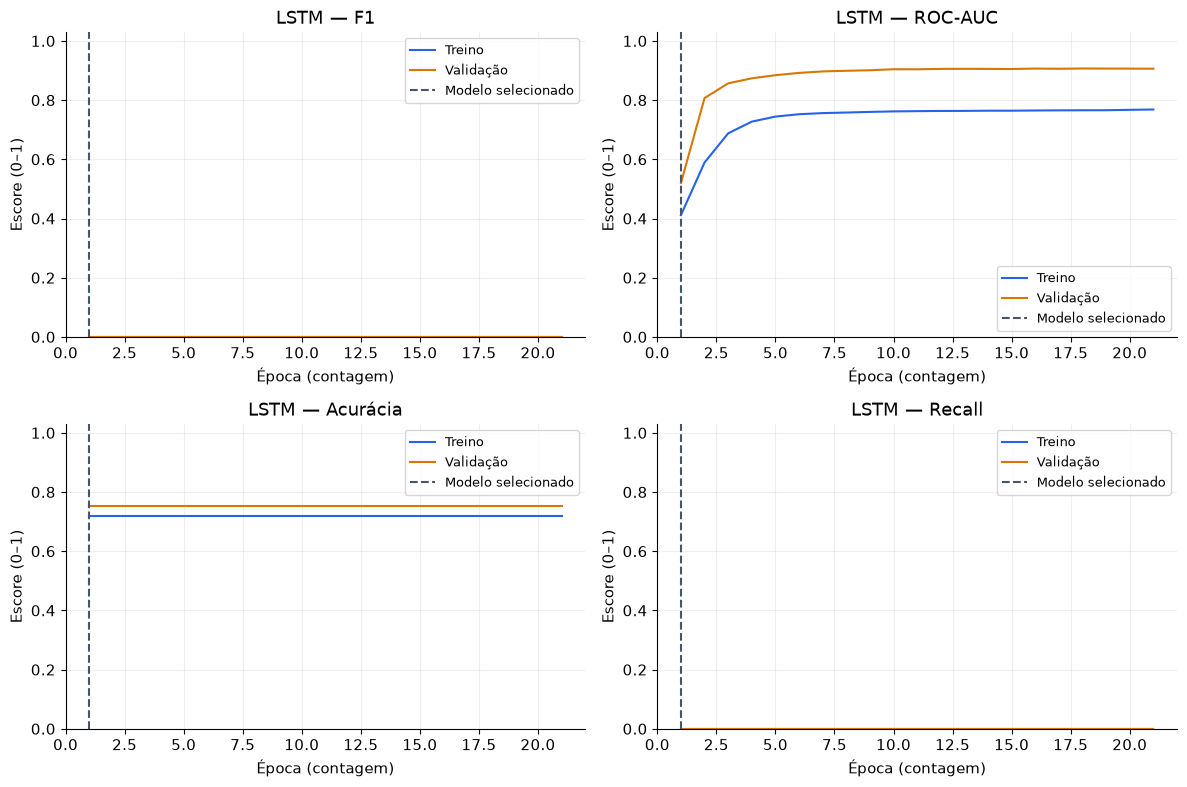

In [27]:
STEP_LABEL = "Época (contagem)"

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (metric, label) in zip(axes.flat, METRIC_LABELS.items()):
    for split in ['treino', 'validacao']:
        subset = history[history.split == split]
        ax.plot(subset.step, subset[metric], color=COLORS[split], label=SPLIT_LABELS[split])
    ax.axvline(selected_step, color='#475569', linestyle='--', label='Modelo selecionado')
    ax.set(title=f'{MODEL_TITLE} — {label}', xlabel=STEP_LABEL, ylabel='Escore (0–1)', ylim=(0, 1.03))
    ax.legend(fontsize=9)
save_figure(fig, '01_historico_metricas')

### 7.3. Validação e teste

,f1,roc_auc,accuracy,recall
split,,,,
treino,0.0,0.4114,0.7184,0.0
validacao,0.0,0.5199,0.7516,0.0
teste,0.0,0.5250,0.6993,0.0


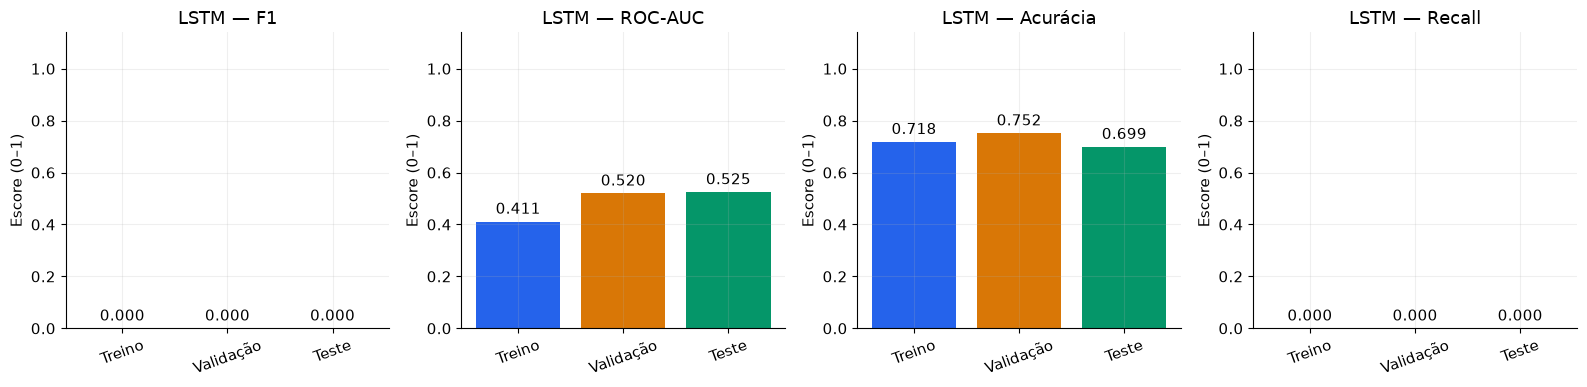

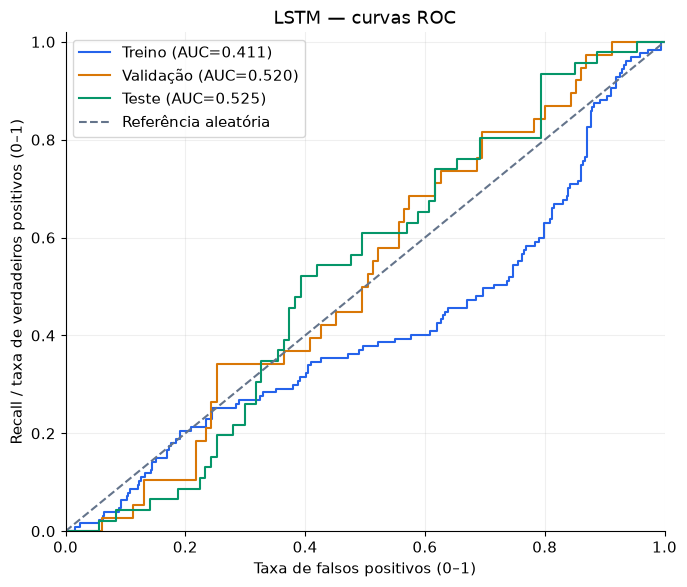

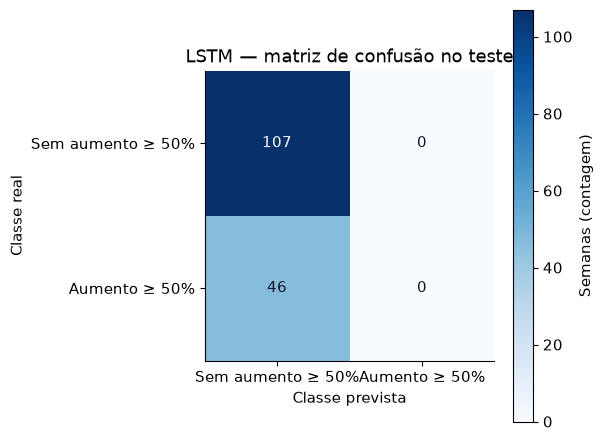

In [28]:
# Avaliação final: nenhuma decisão de seleção é tomada usando o teste.
probabilities = {}
for split in split_ids:
    with torch.no_grad():
        probabilities[split] = torch.sigmoid(model(tensors[split])).cpu().numpy()
metric_rows = []
roc_rows = []
reports = {}
for split, prob in probabilities.items():
    assert len(prob) == len(y[split]) and np.isfinite(prob).all()
    metric_rows.append({'split': split, **calculate_metrics(y[split], prob)})
    prediction = (prob >= THRESHOLD).astype(int)
    pd.DataFrame({'sample_id': split_ids[split], 'target': y[split],
        'probability_positive': prob, 'prediction': prediction}).to_csv(
            DIRS['data'] / f'previsoes_{split}.csv', index=False)
    fpr, tpr, thresholds = roc_curve(y[split], prob)
    roc_rows.extend({'split': split, 'false_positive_rate': float(a),
        'true_positive_rate': float(b), 'threshold': float(c) if np.isfinite(c) else None}
        for a, b, c in zip(fpr, tpr, thresholds))
    pd.DataFrame(confusion_matrix(y[split], prediction, labels=[0, 1]),
        index=['real_sem_aumento', 'real_aumento'], columns=['previsto_sem_aumento', 'previsto_aumento']).to_csv(
            DIRS['metrics'] / f'matriz_confusao_{split}.csv')
    reports[split] = classification_report(y[split], prediction, labels=[0, 1],
        target_names=['sem_aumento', 'aumento'], output_dict=True, zero_division=0)
metrics = pd.DataFrame(metric_rows).set_index('split')
metrics.to_csv(DIRS['metrics'] / 'metricas_finais.csv')
pd.DataFrame(roc_rows).to_csv(DIRS['metrics'] / 'curvas_roc.csv', index=False)
(DIRS['metrics'] / 'relatorios_classificacao.json').write_text(
    json.dumps(reports, indent=2, ensure_ascii=False, allow_nan=False), encoding='utf-8')
display(metrics.round(4))

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (metric, label) in zip(axes, METRIC_LABELS.items()):
    bars = ax.bar([SPLIT_LABELS[s] for s in metrics.index], metrics[metric],
                  color=[COLORS[s] for s in metrics.index])
    ax.set(title=f'{MODEL_TITLE} — {label}', ylabel='Escore (0–1)', ylim=(0, 1.14))
    ax.tick_params(axis='x', rotation=20)
    ax.bar_label(bars, fmt='%.3f', padding=3)
save_figure(fig, '02_metricas_finais')

fig, ax = plt.subplots(figsize=(7, 6))
for split, prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y[split], prob)
    ax.plot(fpr, tpr, color=COLORS[split],
            label=f'{SPLIT_LABELS[split]} (AUC={metrics.loc[split, "roc_auc"]:.3f})')
ax.plot([0, 1], [0, 1], '--', color='#64748B', label='Referência aleatória')
ax.set(title=f'{MODEL_TITLE} — curvas ROC', xlabel='Taxa de falsos positivos (0–1)',
       ylabel='Recall / taxa de verdadeiros positivos (0–1)', xlim=(0, 1), ylim=(0, 1.02))
ax.legend()
save_figure(fig, '03_curvas_roc')

cm = confusion_matrix(y['teste'], (probabilities['teste'] >= THRESHOLD).astype(int), labels=[0, 1])
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap='Blues')
for (i, j), value in np.ndenumerate(cm):
    ax.text(j, i, str(value), ha='center', va='center', color='white' if value > cm.max()/2 else '#0F172A')
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['Sem aumento ≥ 50%', 'Aumento ≥ 50%'],
       yticklabels=['Sem aumento ≥ 50%', 'Aumento ≥ 50%'], xlabel='Classe prevista', ylabel='Classe real',
       title=f'{MODEL_TITLE} — matriz de confusão no teste')
ax.grid(False)
fig.colorbar(im, ax=ax, label='Semanas (contagem)')
save_figure(fig, '04_matriz_confusao_teste')

### 7.4. Explicabilidade

In [29]:
def export_attributions(values, method, units):
    assert values.shape == X['teste'].shape
    assert np.isfinite(values).all()
    local = pd.DataFrame(values, columns=feature_names, index=test_ids)
    local.index.name = 'sample_id'
    local.to_csv(DIRS['explainability'] / f'{method}_atribuicoes.csv')
    importance = pd.DataFrame({'feature': feature_names,
        'mean_absolute_attribution': np.abs(values).mean(axis=0),
        'mean_signed_attribution': values.mean(axis=0)}).sort_values(
            'mean_absolute_attribution', ascending=False)
    importance.to_csv(DIRS['explainability'] / f'{method}_importancia.csv', index=False)
    top = importance.head(15).iloc[::-1]
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(top.feature, top.mean_absolute_attribution, color=COLORS[method])
    ax.set(title=f'{MODEL_TITLE} — {method.replace("_", " ").title()} — teste',
           xlabel=f'Média da atribuição absoluta ({units})', ylabel='Atributo padronizado')
    save_figure(fig, f'05_{method}_importancia')
    display(importance.head(10))
    return importance

/media/lorenzo/SSD/Projetos/ML-Dengue/.venv/lib/python3.12/site-packages/captum/attr/_utils/batching.py:51: UserWarning: Internal batch size cannot be less than the number of input examples. Defaulting to internal batch size of 153 equal to the number of examples.
  warnings.warn(


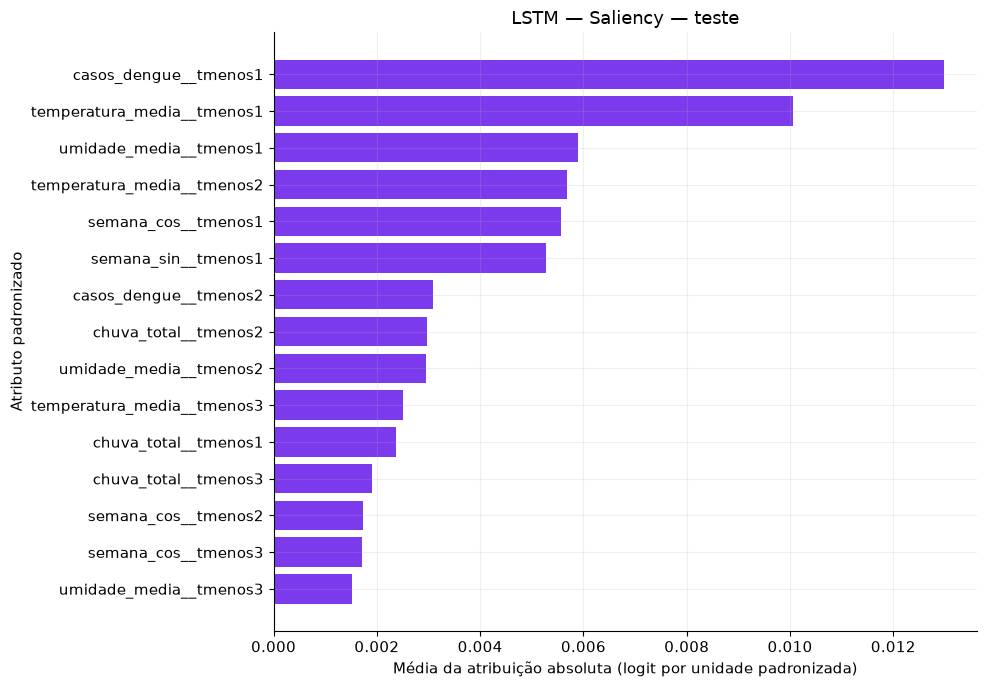

,feature,mean_absolute_attribution,mean_signed_attribution
66,casos_dengue__tmenos1,0.012971,0.012971
67,temperatura_media__tmenos1,0.010055,-0.010055
68,umidade_media__tmenos1,0.005888,0.005839
61,temperatura_media__tmenos2,0.005681,-0.005681
71,semana_cos__tmenos1,0.005562,-0.005454
70,semana_sin__tmenos1,0.005266,-0.005266
60,casos_dengue__tmenos2,0.003080,0.003072
63,chuva_total__tmenos2,0.002969,0.002958
62,umidade_media__tmenos2,0.002952,0.002946
55,temperatura_media__tmenos3,0.002514,-0.002514


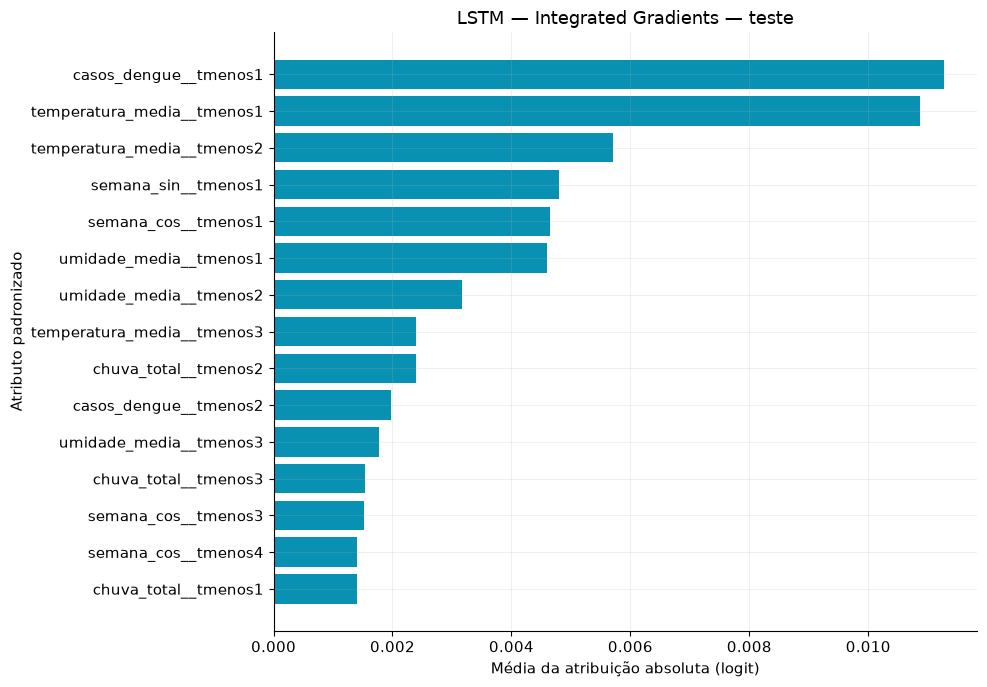

,feature,mean_absolute_attribution,mean_signed_attribution
66,casos_dengue__tmenos1,0.011265,0.009696
67,temperatura_media__tmenos1,0.010867,-0.001201
61,temperatura_media__tmenos2,0.005715,-0.000993
70,semana_sin__tmenos1,0.004801,0.000670
71,semana_cos__tmenos1,0.004645,-0.000942
68,umidade_media__tmenos1,0.004600,-0.001895
62,umidade_media__tmenos2,0.003174,-0.001505
55,temperatura_media__tmenos3,0.002395,-0.000518
63,chuva_total__tmenos2,0.002391,-0.000484
60,casos_dengue__tmenos2,0.001976,0.001682


Maior erro absoluto de completude IG: 4.0978193e-08


In [30]:
# A saída explicada é o logit de crescimento de casos; zero padronizado = média do treino.
model.eval()
inputs = tensors['teste'].detach().clone().requires_grad_(True)
baseline = torch.zeros_like(inputs)
saliency = Saliency(model).attribute(inputs, abs=False).detach().cpu().numpy().reshape(len(test_ids), -1)
ig_values, delta = IntegratedGradients(model).attribute(
    inputs, baselines=baseline, n_steps=256, internal_batch_size=32,
    return_convergence_delta=True)
integrated_gradients = ig_values.detach().cpu().numpy().reshape(len(test_ids), -1)
export_attributions(saliency, 'saliency', 'logit por unidade padronizada')
export_attributions(integrated_gradients, 'integrated_gradients', 'logit')
with torch.no_grad():
    baseline_logit = model(baseline).cpu().numpy()
    predicted_logit = model(inputs).cpu().numpy()
completeness = pd.DataFrame({'sample_id': test_ids, 'baseline_logit': baseline_logit,
    'predicted_logit': predicted_logit, 'sum_attributions': integrated_gradients.sum(axis=1),
    'convergence_delta': delta.detach().cpu().numpy()})
completeness.to_csv(DIRS['explainability'] / 'integrated_gradients_convergencia.csv', index=False)
assert np.isfinite(completeness.to_numpy()).all()
assert np.abs(completeness.convergence_delta).max() < 0.01
print('Maior erro absoluto de completude IG:', np.abs(completeness.convergence_delta).max())

### 7.5. Exportação do modelo e metadados

In [31]:
metadata = {'model':MODEL_KEY,'experiment':EXPERIMENT_NAME,'include_oni':INCLUDE_ONI,
    'dataset':str(DATA_PATH.relative_to(PROJECT_ROOT)), 'seed':SEED,
    'positive_class':'aumento de pelo menos 50% nos casos',
    'target_definition':'casos(t+4) >= 1.5 × média de casos(t−4 ... t−1)',
    'horizon_weeks':HORIZON_WEEKS,'growth_fraction':GROWTH_FRACTION,
    'baseline_weeks':BASELINE_WEEKS,'threshold':THRESHOLD,'selection_metric':'validation_f1',
    'selected_step':int(selected_step),'sequence_length':SEQUENCE_LENGTH,
    'input_features':input_features,'features':feature_names,'availability_lags_weeks':availability_lags,
    'train_end':train_end.date().isoformat(),'validation_end':validation_end.date().isoformat(),
    'test_used_for_selection':False,'colors':COLORS,'font':'DejaVu Sans',
    'units':{'metrics':'escore (0–1)','probabilities':'0–1','casos_dengue':'casos por semana',
      'temperatura_media':'°C','umidade_media':'%','chuva_total':'mm por semana',
      'ONI':'°C (anomalia do índice, conforme a coluna da base)',
      'semana_sin':'adimensional','semana_cos':'adimensional','processed_features':'desvios padrão (DP)',
      'shap':'probabilidade positiva (0–1)','saliency':'logit por unidade padronizada',
      'integrated_gradients':'logit','gini':'importância normalizada (0–1)'},
    'versions':{p:importlib.metadata.version(p) for p in
       ['numpy','pandas','scikit-learn','torch','captum','shap','matplotlib']},
    'limitations':['Aumento de casos é um proxy exploratório; não confirma surto epidemiológico.',
                   'Latências de uma semana (casos/clima) e quatro semanas (ONI) são hipóteses de disponibilidade.',
                   'Um município, uma divisão temporal e uma semente; comparação exploratória.']}
(RESULTS / 'metadata.json').write_text(json.dumps(metadata,indent=2,ensure_ascii=False,allow_nan=False),encoding='utf-8')
model_metrics[MODEL_KEY]=metrics.copy()
selected_models[MODEL_KEY]=model

## 8. Comparação final das três arquiteturas

    O teste é exibido após a seleção individual pela validação. A tabela não escolhe
    hiperparâmetros nem modifica os modelos. Para responder sobre ONI, compare depois
    cada arquitetura com sua correspondente no outro experimento, não apenas os melhores
    resultados de arquiteturas diferentes.

,model,f1,roc_auc,accuracy,recall
0,random_forest,0.7042,0.9303,0.8627,0.5435
1,rnn,0.8090,0.9173,0.8889,0.7826
2,lstm,0.0000,0.5250,0.6993,0.0000


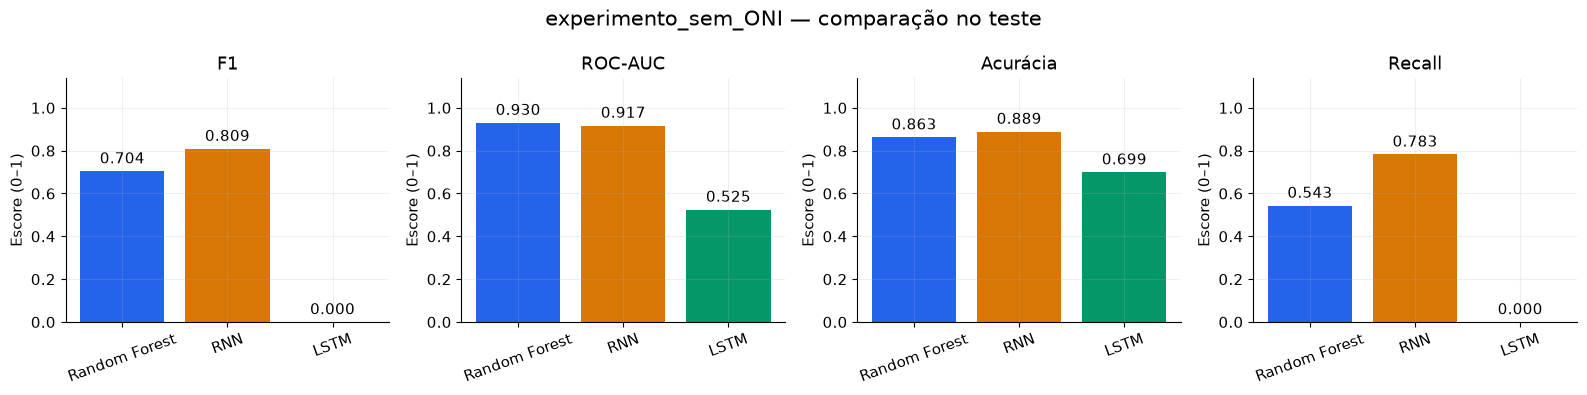

In [32]:
comparison_dir=RESULTS_ROOT/'comparacao'
comparison_dir.mkdir(exist_ok=True)
comparison=pd.DataFrame([{'model':key,**frame.loc['teste'].to_dict()} for key,frame in model_metrics.items()])
comparison.to_csv(comparison_dir/'metricas_teste.csv',index=False)
all_metrics=pd.concat(model_metrics,names=['model','split']).reset_index()
all_metrics.to_csv(comparison_dir/'metricas_todas_particoes.csv',index=False)
display(comparison.round(4))
DIRS={'figures':RESULTS_ROOT/'figures'}
fig,axes=plt.subplots(1,4,figsize=(16,4))
for ax,(metric,label) in zip(axes,METRIC_LABELS.items()):
    bars=ax.bar(['Random Forest','RNN','LSTM'],comparison[metric],color=['#2563EB','#D97706','#059669'])
    ax.bar_label(bars,fmt='%.3f',padding=3)
    ax.set(title=label,ylabel='Escore (0–1)',ylim=(0,1.14))
    ax.tick_params(axis='x',rotation=20)
fig.suptitle(f'{EXPERIMENT_NAME} — comparação no teste',fontsize=15)
save_figure(fig,'comparacao_modelos_teste')

## 9. Exportação JSON e inventário

    `results/data`: dados e partições compartilhadas; `results/eda`: tabelas exploratórias;
    `results/figures`: EDA e comparação; cada arquitetura tem sua subpasta em `results`.
    `results/json` espelha os CSVs e `results/app_resultados.json` reúne tabelas,
    metadados, relatórios e dados para reconstruir os gráficos.

In [33]:
# Exportação comum: todos os CSVs ganham JSON; inclui séries dos gráficos existentes.
def export_json_results(root):
    root=Path(root)
    tables={}
    for path in sorted(root.rglob('*.csv')):
        if 'json' in path.relative_to(root).parts or path.name=='manifest.csv':continue
        frame=pd.read_csv(path)
        if frame.columns[0].startswith('Unnamed:'):
            frame=frame.rename(columns={frame.columns[0]:'classe_real'})
        frame=frame.replace([np.inf,-np.inf],np.nan)
        records=json.loads(frame.to_json(orient='records',force_ascii=False,double_precision=15))
        relative=path.relative_to(root).with_suffix('.json')
        destination=root/'json'/relative
        destination.parent.mkdir(parents=True,exist_ok=True)
        destination.write_text(json.dumps(records,indent=2,ensure_ascii=False,allow_nan=False),encoding='utf-8')
        tables[str(path.relative_to(root).with_suffix(''))]=records
    graph_data=[]
    for key,title in [('random_forest','Random Forest'),('rnn','RNN'),('lstm','LSTM')]:
        for metric,label in METRIC_LABELS.items():
            graph_data.append({'id':f'{key}/historico/{metric}','titulo':f'{title} — {label}',
                'tipo':'linha','eixoX':'Árvores (contagem)' if key=='random_forest' else 'Época (contagem)',
                'eixoY':'Escore (0–1)','series':[{'id':split,'cor':COLORS[split],
                    'pontos':[{'x':r['step'],'y':r[metric]} for r in tables[f'{key}/metrics/historico_treinamento'] if r['split']==split]}
                    for split in ['treino','validacao']]})
            graph_data.append({'id':f'{key}/metricas/{metric}','titulo':f'{title} — {label}',
                'tipo':'barras','eixoX':'Partição','eixoY':'Escore (0–1)',
                'series':[{'id':r['split'],'cor':COLORS[r['split']],
                    'pontos':[{'x':SPLIT_LABELS[r['split']],'y':r[metric]}]}
                    for r in tables[f'{key}/metrics/metricas_finais']]})
        graph_data.append({'id':f'{key}/roc','titulo':f'{title} — curvas ROC','tipo':'linha',
            'eixoX':'Taxa de falsos positivos (0–1)','eixoY':'Recall (0–1)',
            'series':[{'id':split,'cor':COLORS[split],'pontos':[{'x':r['false_positive_rate'],
             'y':r['true_positive_rate'],'limiar':r['threshold']} for r in tables[f'{key}/metrics/curvas_roc'] if r['split']==split]}
             for split in SPLIT_LABELS]})
        cm=tables[f'{key}/metrics/matriz_confusao_teste']
        graph_data.append({'id':f'{key}/matriz_confusao','titulo':f'{title} — matriz de confusão no teste',
            'tipo':'mapa_calor','eixoX':'Classe prevista','eixoY':'Classe real','unidade':'Semanas (contagem)',
            'rotulos':['Sem aumento ≥ 50%','Aumento ≥ 50%'],
            'valores':[[r['previsto_sem_aumento'],r['previsto_aumento']] for r in cm]})
        methods=['shap','gini'] if key=='random_forest' else ['saliency','integrated_gradients']
        for method in methods:
            rows=tables[f'{key}/explainability/{method}_importancia']
            field='importance' if method=='gini' else 'mean_absolute_attribution'
            units={'shap':'probabilidade positiva (0–1)','gini':'importância normalizada (0–1)',
                   'saliency':'logit por unidade padronizada','integrated_gradients':'logit'}
            graph_data.append({'id':f'{key}/explicabilidade/{method}',
                'titulo':f'{title} — {method}','tipo':'barras_horizontais','eixoX':units[method],
                'eixoY':'Atributo e defasagem','series':[{'id':method,'cor':COLORS[method],
                    'pontos':[{'x':r[field],'y':r['feature'],**({'erroX':r['std_across_trees']} if method=='gini' else {})}
                              for r in rows[:15][::-1]]}]})
    for feature in input_features:
        graph_data.append({'id':f'eda/histograma/{feature}','titulo':f'Treino — {feature}','tipo':'histograma',
            'eixoX':'Valor padronizado (DP)','eixoY':'Semanas (contagem)',
            'series':[{'id':'treino','cor':COLORS['treino'],'pontos':[
                {'x':r['bin_center'],'y':r['count'],'limiteInferior':r['bin_left'],'limiteSuperior':r['bin_right']}
                for r in tables['eda/histogramas_treino'] if r['feature']==feature]}]})
    graph_data.append({'id':'eda/classes','titulo':'Distribuição das classes','tipo':'barras_agrupadas',
        'eixoX':'Partição','eixoY':'Semanas (contagem)','dados':tables['eda/distribuicao_classes']})
    graph_data.append({'id':'eda/gini','titulo':'Impureza Gini das classes','tipo':'barras',
        'eixoX':'Partição','eixoY':'Impureza Gini (0–0,5)','dados':tables['eda/gini_classes']})
    graph_data.append({'id':'eda/boxplots','titulo':'Boxplots por classe no treino','tipo':'boxplot_horizontal',
        'eixoX':'Valor padronizado (DP)','eixoY':'Atributo','estatisticas':tables['eda/boxplots_treino'],
        'outliers':tables['eda/boxplots_outliers']})
    correlation={(r['feature_y'],r['feature_x']):r['correlation'] for r in tables['eda/correlacoes_treino']}
    graph_data.append({'id':'eda/correlacoes','titulo':'Correlação de Pearson no treino','tipo':'mapa_calor',
        'rotulosX':input_features,'rotulosY':input_features,'minimo':-1,'maximo':1,
        'valores':[[correlation[(a,b)] for b in input_features] for a in input_features]})
    graph_data.append({'id':'eda/ausentes','titulo':'Valores ausentes no treino','tipo':'barras_horizontais',
        'eixoX':'Valores ausentes (contagem)','eixoY':'Atributo','dados':tables['eda/valores_ausentes_treino']})
    graph_data.append({'id':'comparacao/modelos','titulo':'Comparação no teste','tipo':'barras_agrupadas',
        'eixoX':'Modelo','eixoY':'Escore (0–1)','dados':tables['comparacao/metricas_teste']})
    metadata={key:json.loads((root/key/'metadata.json').read_text()) for key in model_metrics}
    reports={key:json.loads((root/key/'metrics/relatorios_classificacao.json').read_text()) for key in model_metrics}
    payload={'schemaVersion':'1.0.0','experimento':EXPERIMENT_NAME,'incluiONI':INCLUDE_ONI,
        'pergunta':'ONI melhora a previsão de aumento de pelo menos 50% nos casos daqui a quatro semanas?',
        'configuracao':{'horizonteSemanas':HORIZON_WEEKS,'aumentoMinimo':GROWTH_FRACTION,
          'semanasReferencia':BASELINE_WEEKS,'semanasEntrada':SEQUENCE_LENGTH,'limiar':THRESHOLD,'seed':SEED},
        'estilo':{'fonte':'DejaVu Sans','cores':COLORS},'metadadosModelos':metadata,
        'tabelas':tables,'relatoriosClassificacao':reports,'graficos':graph_data}
    destination=root/'app_resultados.json'
    destination.write_text(json.dumps(payload,indent=2,ensure_ascii=False,allow_nan=False),encoding='utf-8')
    inventory=[{'path':str(p.relative_to(root)),'bytes':p.stat().st_size} for p in sorted(root.rglob('*'))
               if p.is_file() and p.name!='manifest.csv']
    pd.DataFrame(inventory).to_csv(root/'manifest.csv',index=False)
    return destination

json_path=export_json_results(RESULTS_ROOT)
print('JSON consolidado:',json_path)
print('JSONs individuais:',RESULTS_ROOT/'json')

JSON consolidado: /media/lorenzo/SSD/Projetos/ML-Dengue/experimento_sem_ONI/results/app_resultados.json
JSONs individuais: /media/lorenzo/SSD/Projetos/ML-Dengue/experimento_sem_ONI/results/json


## 10. Estabilidade na validação — cinco sementes

Esta rodada mantém o alvo de quatro semanas, os atributos, as datas e o protocolo
de treinamento. Usa sementes **42, 123, 2025, 7 e 99**, sem escolher a melhor.
Somente treino e validação entram nesta rodada; o teste histórico não é reavaliado.

São exportados F1, precisão, recall, ROC-AUC, PR-AUC (Average Precision) e acurácia,
com média, desvio padrão e valores por semente. O desvio padrão mede variação de
treinamento no mesmo período, não incerteza de desempenho em anos novos. A validação
também seleciona checkpoints; seus resultados continuam sendo de desenvolvimento.

**Referência simples:** diferença entre médias dos dois últimos blocos de quatro
semanas, extrapolada linearmente a partir do último caso disponível. A referência
não usa ENSO e não tem parâmetros ajustados pelo desempenho.

**Diagnóstico separado:** a LSTM da semente 42 continua até 150 épocas para examinar
perda, F1 e quantidade de previsões positivas depois da parada original. Essa
continuação não modifica o checkpoint ou as métricas principais.

A execução abaixo é independente das células anteriores e usa os CSVs já gerados.
Resultados em `results/estabilidade`; JSON consolidado e inventário são atualizados.
O código compartilhado está em `models/avaliar_estabilidade.py`.


experimento_sem_ONI random_forest 42 F1 validação = 0.6988


experimento_sem_ONI random_forest 123 F1 validação = 0.7059


experimento_sem_ONI random_forest 2025 F1 validação = 0.7294


experimento_sem_ONI random_forest 7 F1 validação = 0.7317


experimento_sem_ONI random_forest 99 F1 validação = 0.716


experimento_sem_ONI rnn 42 F1 validação = 0.6923


... (5 outputs left out)

experimento_sem_ONI lstm 123 F1 validação = 0.5306


experimento_sem_ONI lstm 2025 F1 validação = 0.6765


experimento_sem_ONI lstm 7 F1 validação = 0.6567


experimento_sem_ONI lstm 99 F1 validação = 0.6667


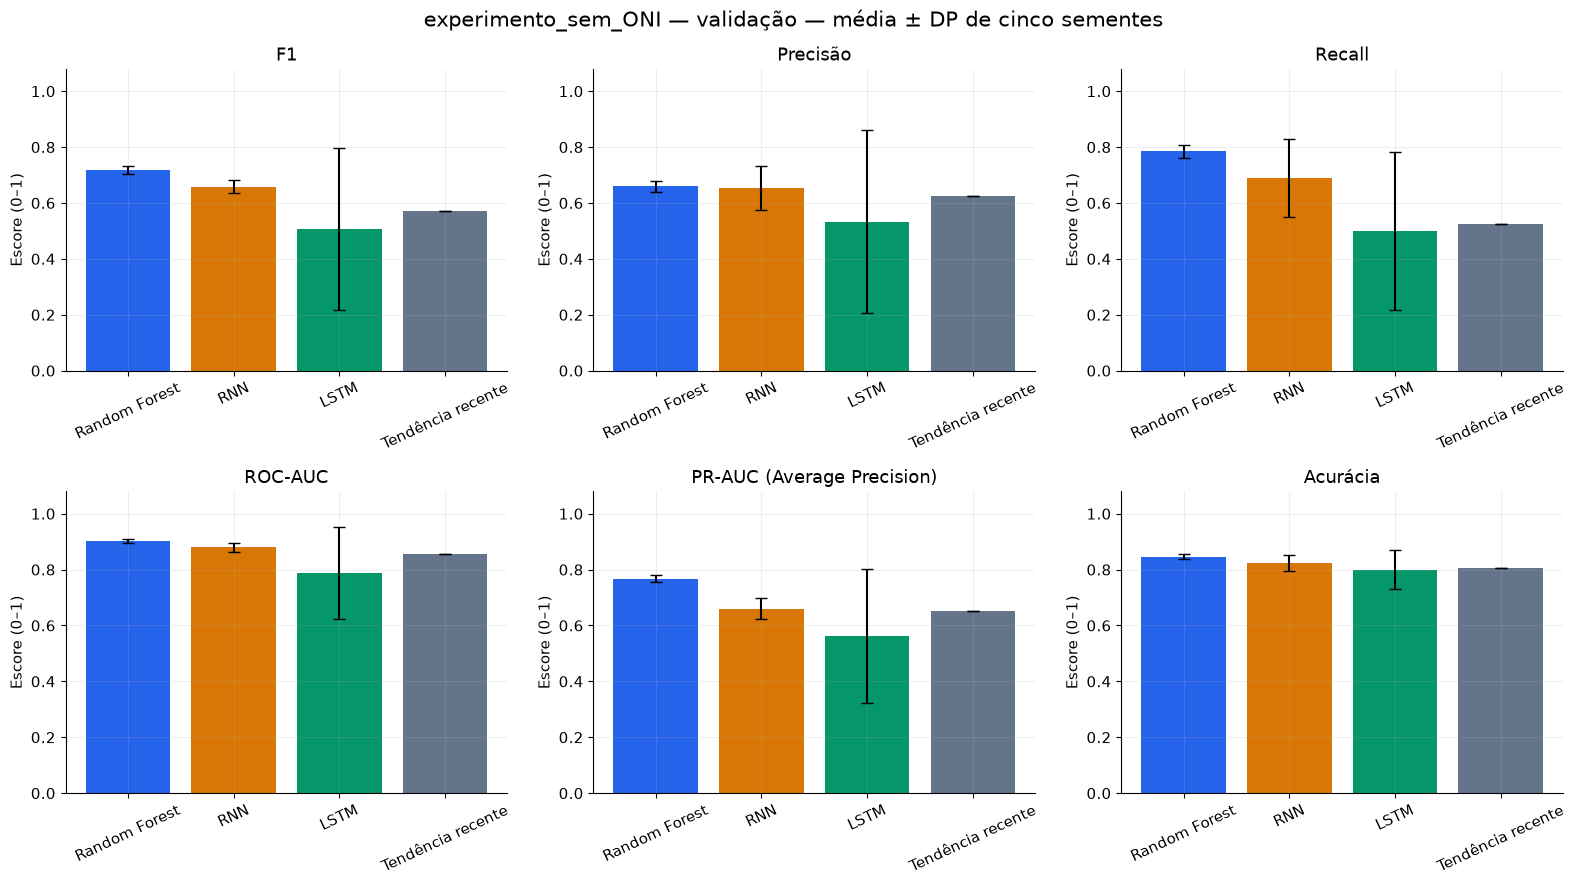

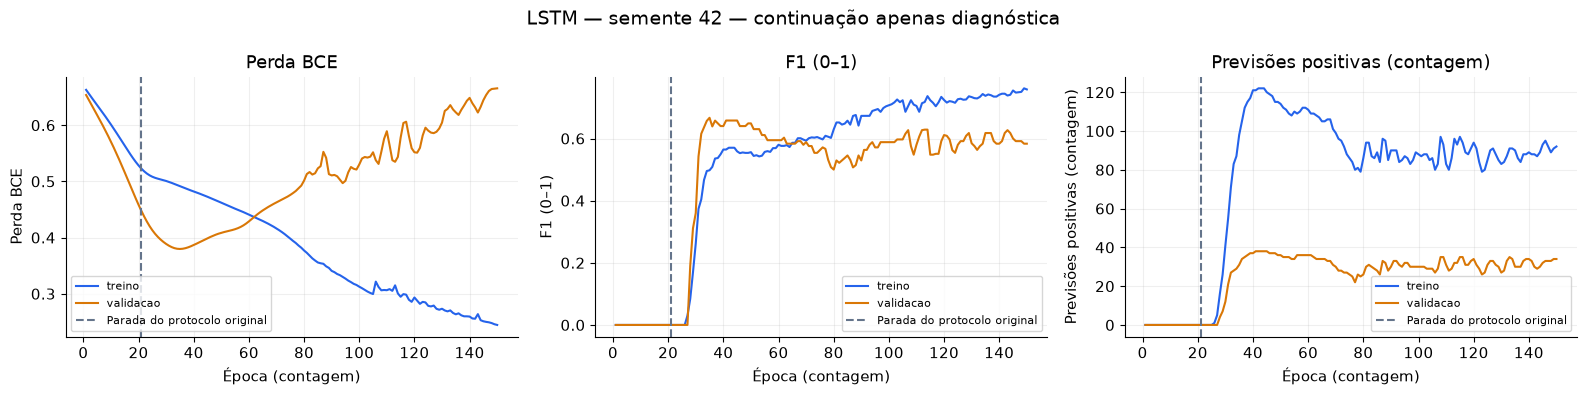

,model,metric,n_runs,mean,std,min,max
0,random_forest,f1,5,0.7164,0.0144,0.6988,0.7317
1,random_forest,precision,5,0.6597,0.0187,0.6383,0.6818
2,random_forest,recall,5,0.7842,0.0220,0.7632,0.8158
3,random_forest,roc_auc,5,0.9022,0.0080,0.8888,0.9078
4,random_forest,pr_auc,5,0.7680,0.0114,0.7545,0.7834
5,random_forest,accuracy,5,0.8458,0.0088,0.8366,0.8562
6,rnn,f1,5,0.6587,0.0232,0.6301,0.6923
7,rnn,precision,5,0.6547,0.0792,0.5224,0.7333
8,rnn,recall,5,0.6895,0.1385,0.5789,0.9211
9,rnn,roc_auc,5,0.8803,0.0165,0.8515,0.8936


Execute a seção de estabilidade do outro experimento para obter a comparação pareada.


In [34]:
from pathlib import Path
import runpy
from IPython.display import display

current = Path.cwd().resolve()
experiment_dir = current if current.name == 'experimento_sem_ONI' else current / 'experimento_sem_ONI'
api = runpy.run_path(str(experiment_dir.parent / 'models/avaliar_estabilidade.py'))
stability_summary = api['run_experiment'](experiment_dir)
display(stability_summary.round(4))
paired_comparison = api['compare_experiments'](experiment_dir.parent)
if paired_comparison is not None:
    display(paired_comparison.round(4))
else:
    print('Execute a seção de estabilidade do outro experimento para obter a comparação pareada.')


## 11. Seleção das redes pela perda de validação

Nesta rodada, somente o critério de seleção de época e parada antecipada das redes
muda: **menor perda BCE na validação**, em vez de maior F1. Mantemos limiar 0,5,
cinco sementes, entradas, alvo, datas, arquitetura, otimizador, taxa de aprendizado,
limite de 150 épocas e paciência de 20. Random Forest mantém a seleção por F1.

A seção 10 e `results/estabilidade` preservam a rodada anterior. Os novos resultados
ficam em `results/estabilidade_perda`, com comparação entre critérios e experimentos.
O teste não é reavaliado e não escolhe ajustes. A continuação diagnóstica da LSTM
permanece separada do checkpoint principal. Resultados da validação são de
 desenvolvimento, não uma confirmação independente.

Esta célula pode ser executada isoladamente usando os CSVs já disponíveis.


experimento_sem_ONI random_forest 42 F1 validação = 0.6988


experimento_sem_ONI random_forest 123 F1 validação = 0.7059


experimento_sem_ONI random_forest 2025 F1 validação = 0.7294


experimento_sem_ONI random_forest 7 F1 validação = 0.7317


experimento_sem_ONI random_forest 99 F1 validação = 0.716


experimento_sem_ONI rnn 42 F1 validação = 0.6269


... (5 outputs left out)

experimento_sem_ONI lstm 123 F1 validação = 0.6377


experimento_sem_ONI lstm 2025 F1 validação = 0.6471


experimento_sem_ONI lstm 7 F1 validação = 0.6567


experimento_sem_ONI lstm 99 F1 validação = 0.6575


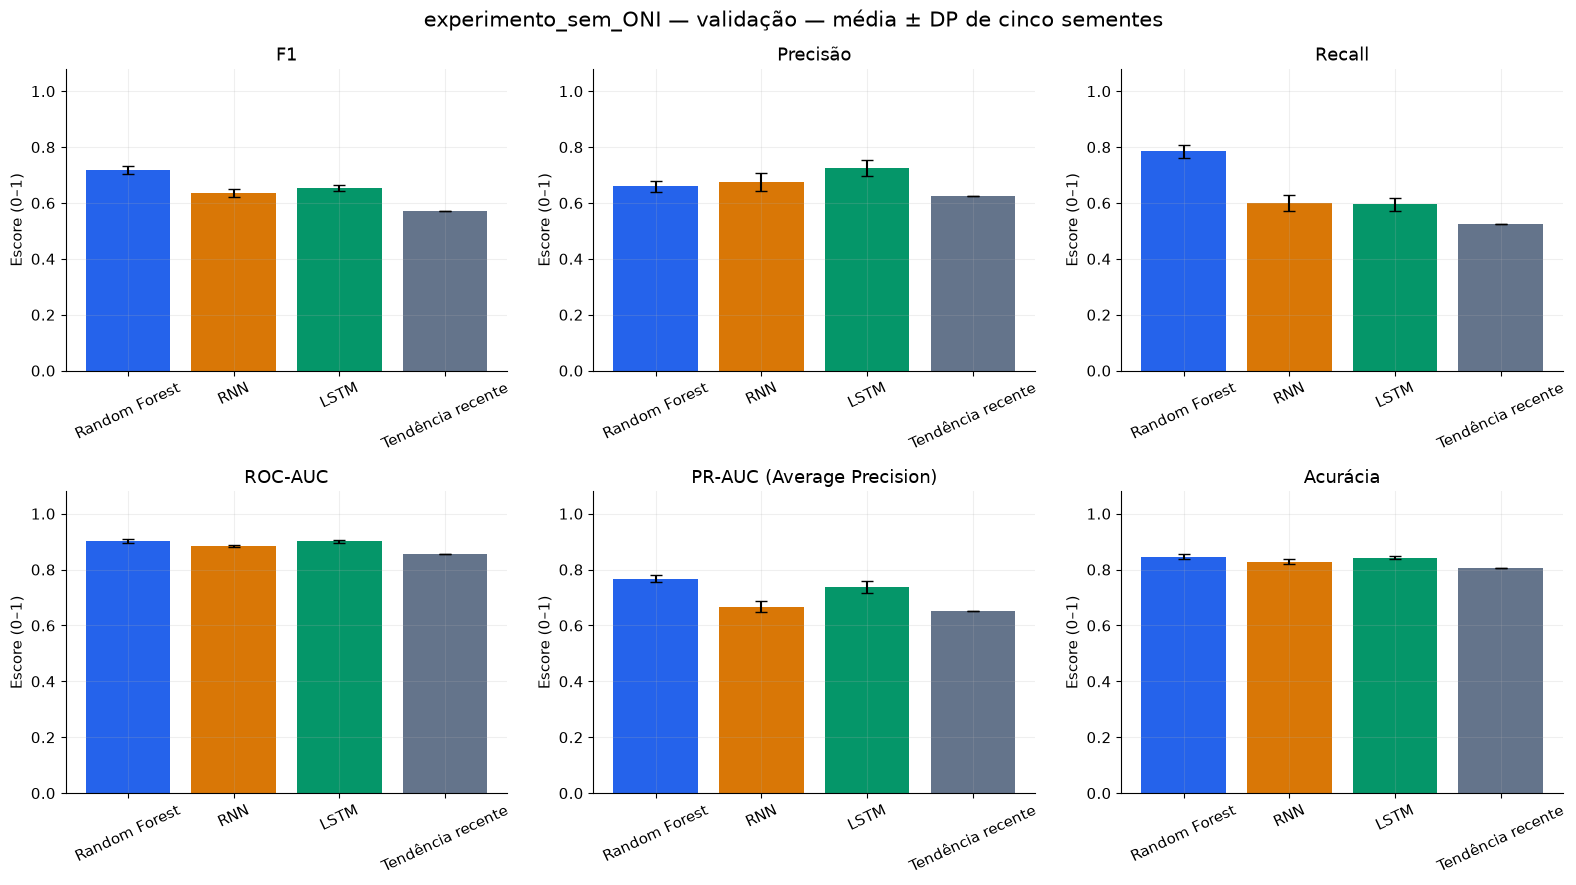

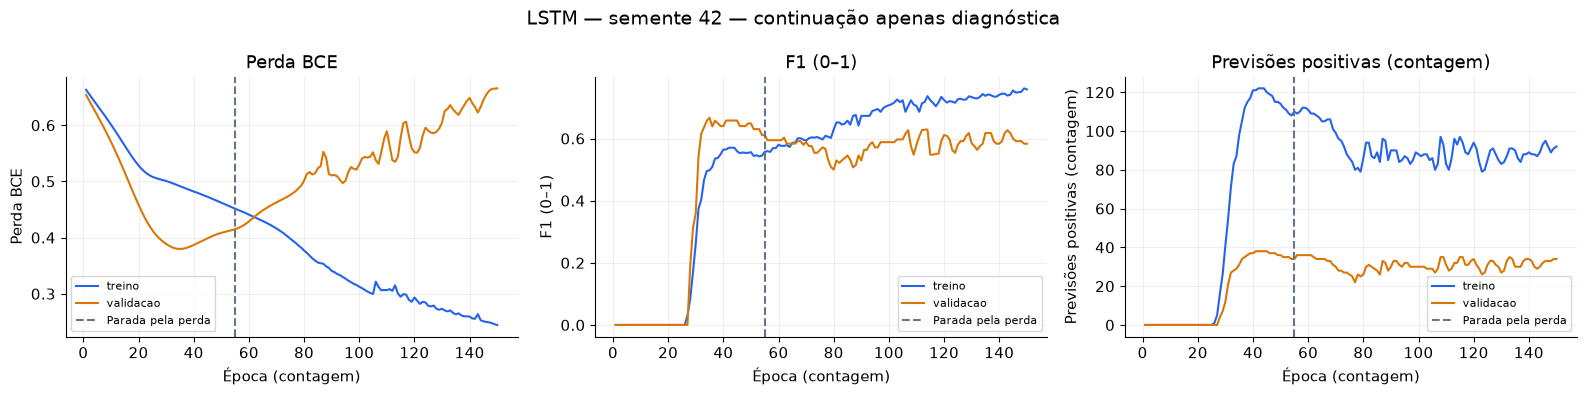

,model,metric,n_runs,mean,std,min,max
0,random_forest,f1,5,0.7164,0.0144,0.6988,0.7317
1,random_forest,precision,5,0.6597,0.0187,0.6383,0.6818
2,random_forest,recall,5,0.7842,0.0220,0.7632,0.8158
3,random_forest,roc_auc,5,0.9022,0.0080,0.8888,0.9078
4,random_forest,pr_auc,5,0.7680,0.0114,0.7545,0.7834
5,random_forest,accuracy,5,0.8458,0.0088,0.8366,0.8562
6,rnn,f1,5,0.6350,0.0141,0.6216,0.6575
7,rnn,precision,5,0.6765,0.0322,0.6389,0.7241
8,rnn,recall,5,0.6000,0.0288,0.5526,0.6316
9,rnn,roc_auc,5,0.8846,0.0030,0.8822,0.8892


Execute a seção 11 do outro experimento para completar as comparações.


In [35]:
from pathlib import Path
import runpy
from IPython.display import display

current = Path.cwd().resolve()
experiment_dir = current if current.name == 'experimento_sem_ONI' else current / 'experimento_sem_ONI'
api = runpy.run_path(str(experiment_dir.parent / 'models/avaliar_estabilidade.py'))
loss_summary = api['run_experiment'](experiment_dir, network_selection='loss')
display(loss_summary.round(4))
loss_comparison = api['compare_experiments'](experiment_dir.parent, network_selection='loss')
if loss_comparison is not None:
    display(loss_comparison.round(4))
else:
    print('Execute a seção 11 do outro experimento para completar as comparações.')
